# Quantitative Astropolitics: Mapping 30-Day Satellite Trajectories and Quantifying Orbital Inequities

**Research Toolkit & Empirical Analysis**  
*Data Source*: CelesTrak (NORAD GP Ephemeris & SATCAT Catalog, 16,092 Space Objects)  
*Propagation Window*: 30 Days (Vectorized SGP4 / WGS84 Geodetic)  

---

## Executive Summary
Outer space is legally framed by Article I of the 1967 Outer Space Treaty (OST) as the *"province of all mankind"*, establishing that outer space shall be free for exploration and use by all States without discrimination of any kind. Article II further codifies the principle of non-appropriation: outer space, including the Moon and other celestial bodies, is not subject to national appropriation by claim of sovereignty, by means of use or occupation, or by any other means.

However, physical and technological reality contradicts this legal ideal. The current orbital distribution of satellites reveals severe structural inequities across key astropolitical dimensions:
1. **Orbital Shell Monopolization (LEO Enclosure)**: Over 88% of active Low Earth Orbit (LEO) satellites are operated by a single US commercial entity (SpaceX/Starlink). The Herfindahl-Hirschman Index (HHI) for LEO asset ownership exceeds **7,780**, indicating an extreme monopoly regime that forecloses orbital real estate to latecomer nations.
2. **Surveillance & Reconnaissance Asymmetry**: Earth observation (EO) platforms are overwhelmingly concentrated among great powers and Western commercial firms, establishing asymmetric transparency over developing nations without reciprocal sovereign oversight.
3. **Latitudinal Dwell Skew**: Because orbital dwell time scales as $dt/d\phi \propto 1/\sqrt{\sin^2(i) - \sin^2(\phi)}$, constellations inclined at ~53° spend disproportionate time over mid-latitudes (North America, Europe, East Asia) relative to the equator.
4. **Environmental Externalities of the Orbital Commons**: The historical space powers responsible for generating tracked debris clouds have imposed heightened collision risks and station-keeping costs on nascent space programs from emerging spacefaring states.
5. **The 2019 Commercial Enclosure Inflection Point**: Over 85% of all active satellites in orbit were deployed after 2019, outpacing the prior 60 years of cumulative sovereign space exploration.
6. **Atmospheric Deorbit Externalities**: The continuous replenishment of mega-constellations injects over 1,000 metric tons of vaporized aerospace aluminum into the upper atmosphere annually.


## 1. Setup & Environment Initialization
We import our modular packages for CelesTrak ingestion, SGP4 vectorized trajectory propagation, inequality metrics, and advanced visualizations.


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import Image, display

# Set project working directory
import sys
sys.path.insert(0, os.path.abspath(".."))

from src.data_pipeline.loader import load_all_satellites
from src.orbit_engine.propagator import OrbitPropagator
from src.analysis.regional import WORLD_REGIONS, calculate_regional_pass_statistics
from src.analysis.metrics import (
    compute_orbital_shell_concentration,
    compute_latitudinal_dwell_distribution,
    compute_earth_observation_revisit_disparity,
    compute_debris_liability_index,
)
from src.analysis.advanced_metrics import (
    compute_temporal_enclosure,
    compute_volumetric_density,
    compute_geo_longitudinal_sovereignty,
    compute_climate_vulnerability_gap,
    compute_atmospheric_deorbit_deposition,
    compute_global_activity_grid,
)

print("Environment loaded successfully.")


Environment loaded successfully.


## 2. Satellite Fleet Ingestion & Demographic Audit
We load the complete active fleet and debris records from our cached CelesTrak dataset (16,092 cataloged objects), mapping NORAD country codes and mission types into macro geopolitical blocs.


In [2]:
df_master = load_all_satellites("../data/raw")
print(f"Total space objects cataloged: {len(df_master):,}")

# Summary breakdown by Mission Cohort
cohort_summary = df_master["MISSION_COHORT"].value_counts().reset_index()
cohort_summary.columns = ["Mission Cohort", "Object Count"]
cohort_summary["Percentage"] = (cohort_summary["Object Count"] / len(df_master) * 100).round(2)
display(cohort_summary)


Total space objects cataloged: 16,092


,Mission Cohort,Object Count,Percentage
0,Commercial Broadband,12111,75.26
1,Orbital Debris,2668,16.58
2,Earth Observation & Surveillance,529,3.29
3,Geostationary Telecom,470,2.92
4,"Positioning, Navigation & Timing (PNT)",153,0.95
5,Sovereign Defense & MilSat,100,0.62
6,Science & Other Payloads,43,0.27
7,Space Stations & Crewed,18,0.11


In [3]:
# Summary breakdown by Geopolitical Bloc
bloc_summary = df_master["GEOPOLITICAL_BLOC"].value_counts().reset_index()
bloc_summary.columns = ["Geopolitical Bloc", "Object Count"]
bloc_summary["Percentage"] = (bloc_summary["Object Count"] / len(df_master) * 100).round(2)
display(bloc_summary)


,Geopolitical Bloc,Object Count,Percentage
0,US Commercial (SpaceX),11204,69.62
1,Other / International,3032,18.84
2,Europe / UK Commercial (OneWeb),651,4.05
3,China Commercial (Qianfan),256,1.59
4,United States (Civil / Defense),252,1.57
5,China (PRC),209,1.30
6,US Commercial (Planet Labs),127,0.79
7,Europe (ESA / EU),77,0.48
8,Russia,74,0.46
9,US Commercial (Spire),70,0.43


## 3. Mission Cohort Breakdown Across Geopolitical Blocs
Here we examine how operational satellites are distributed across functional cohorts (Commercial Broadband, Earth Observation, Navigation/PNT, Defense/MilSat, Geostationary Telecom).


In [4]:
active_df = df_master[df_master["OBJECT_TYPE"] != "DEB"]
cohort_cross = pd.crosstab(active_df["MISSION_COHORT"], active_df["GEOPOLITICAL_BLOC"])
display(cohort_cross)


GEOPOLITICAL_BLOC,China (PRC),China Commercial (Qianfan),Europe (ESA / EU),Europe / UK Commercial (OneWeb),Global South,India (ISRO),Japan (JAXA),Other / International,Russia,US Allied Partners,US Commercial (Planet Labs),US Commercial (SpaceX),US Commercial (Spire),United States (Civil / Defense)
MISSION_COHORT,,,,,,,,,,,,,,
Commercial Broadband,0,256,0,651,0,0,0,0,0,0,0,11204,0,0
Earth Observation & Surveillance,70,0,41,0,11,20,31,82,11,0,127,0,70,66
Geostationary Telecom,77,0,4,0,14,31,24,232,25,7,0,0,0,56
"Positioning, Navigation & Timing (PNT)",56,0,32,0,0,0,0,0,33,0,0,0,0,32
Science & Other Payloads,0,0,0,0,0,0,0,43,0,0,0,0,0,0
Sovereign Defense & MilSat,0,0,0,0,0,0,0,5,0,0,0,0,0,95
Space Stations & Crewed,6,0,0,0,1,0,1,3,4,0,0,0,0,3


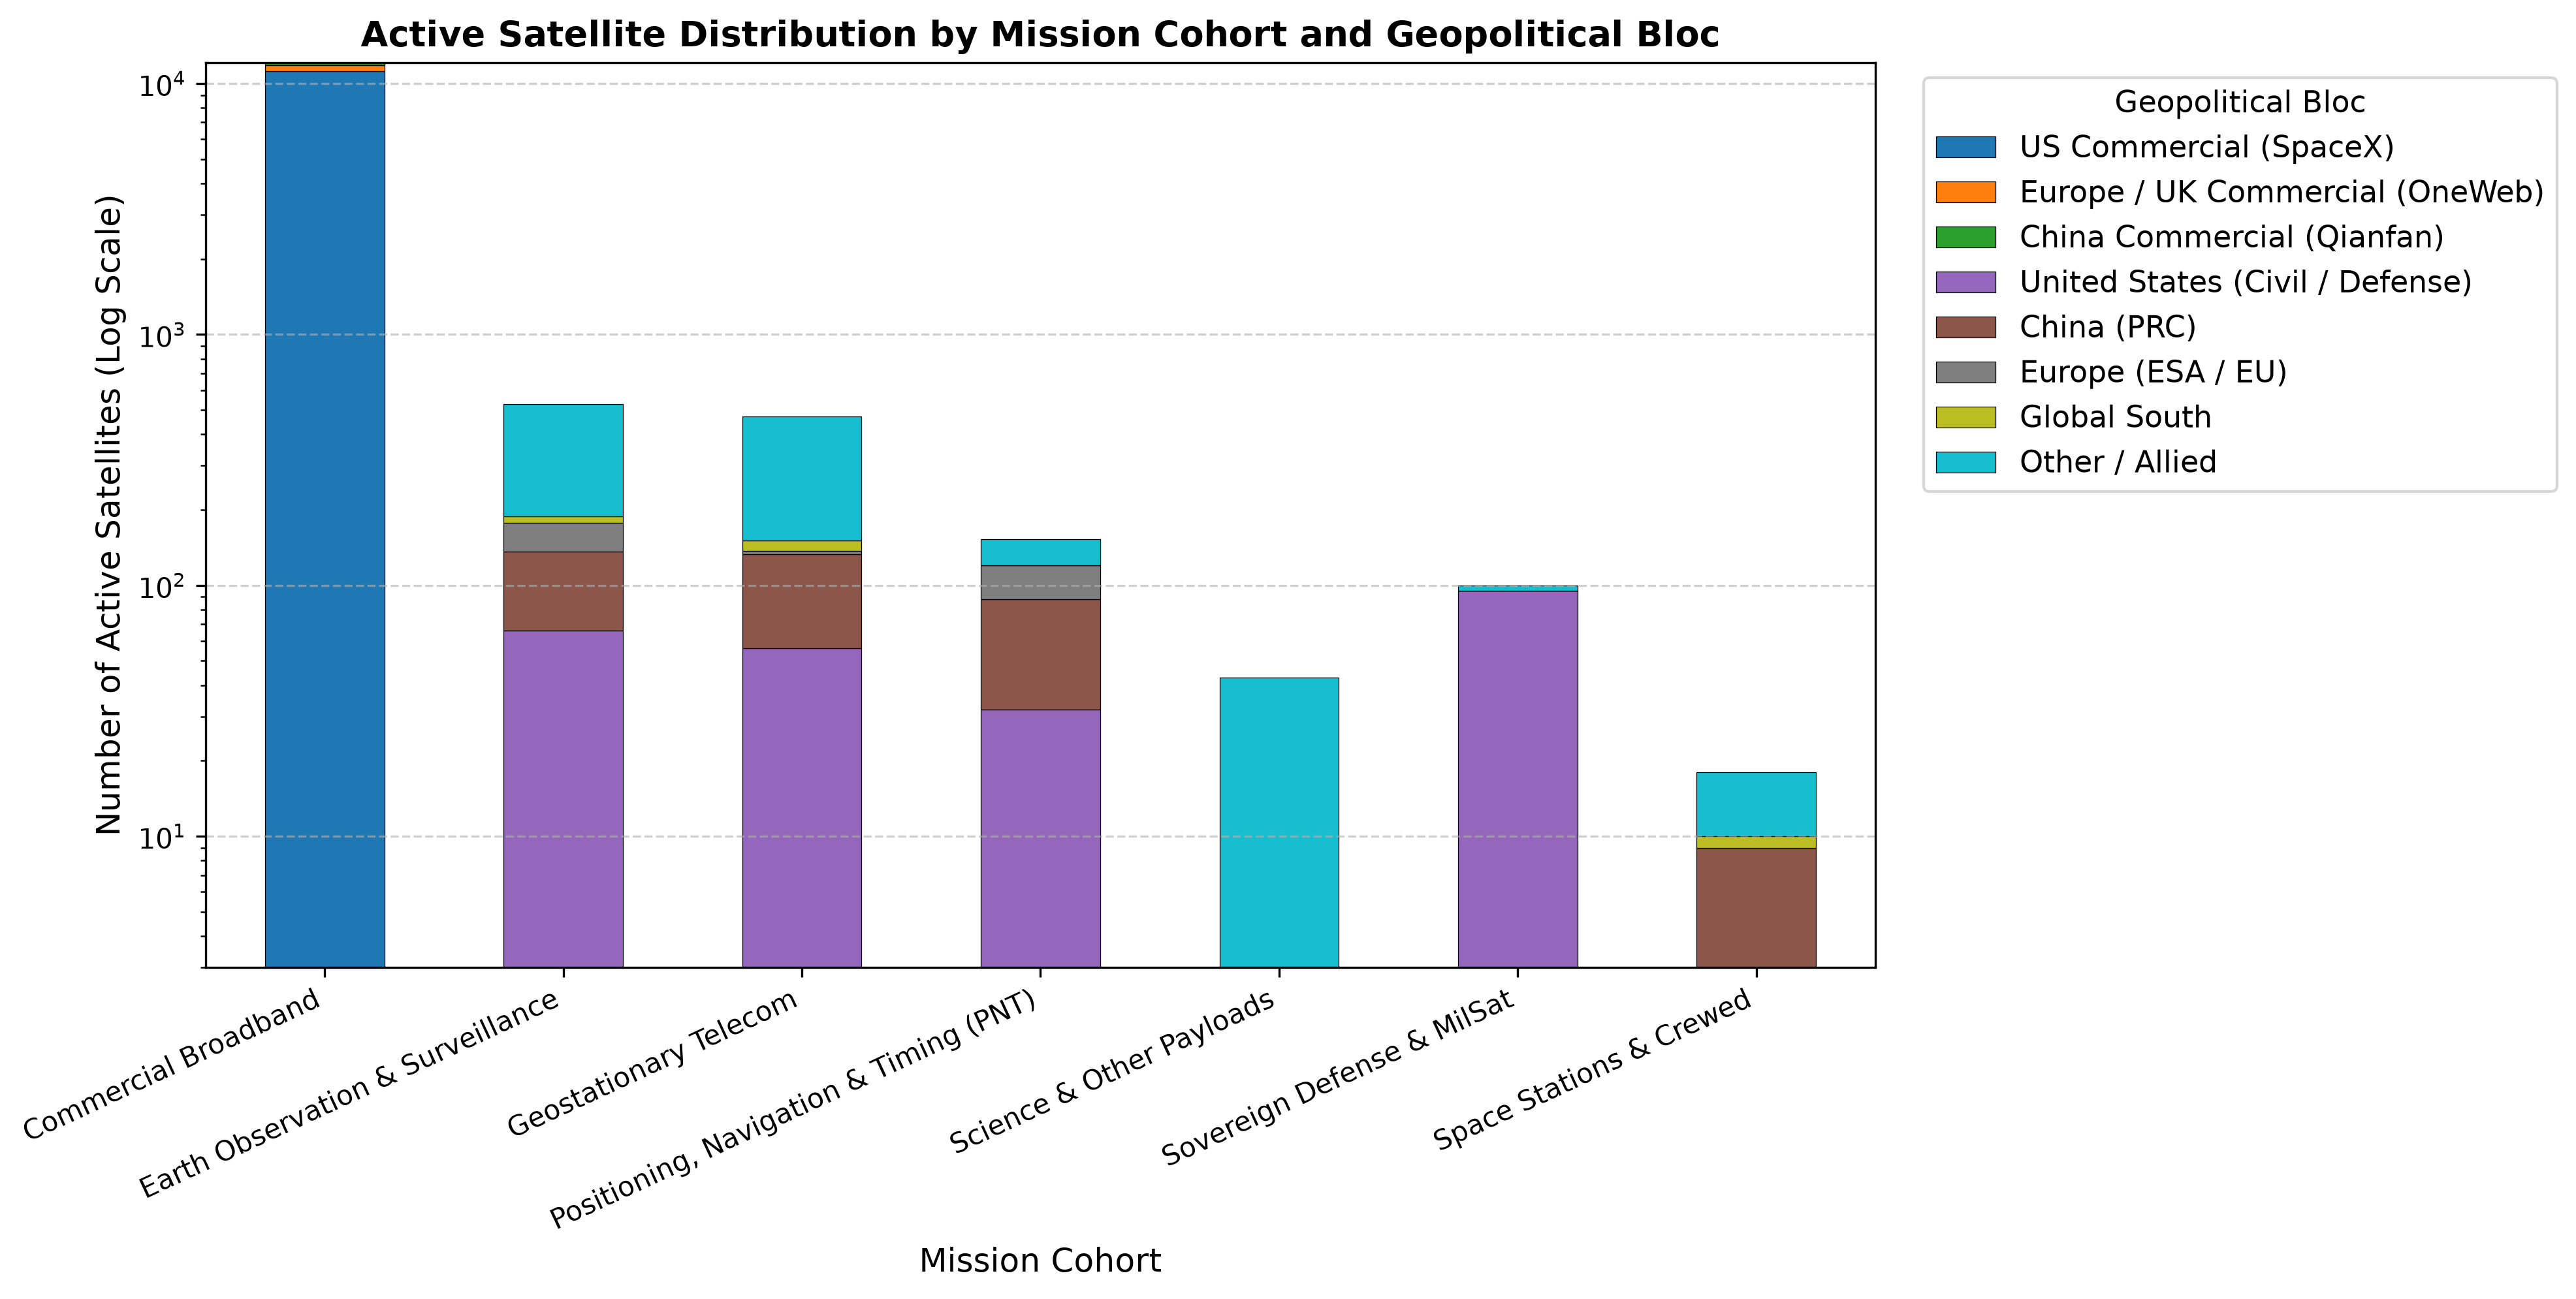

In [5]:
fig_path = "../output/figures/mission_cohort_breakdown.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 4. Astropolitical Concentration: Gini Coefficient & HHI
We evaluate market and sovereign concentration across orbital shells:
- **Low Earth Orbit (LEO)**: 200 km to 2,000 km altitude.
- **Herfindahl-Hirschman Index (HHI)**: Standard economic measure of concentration (0 to 10,000). Any score >2,500 represents severe market concentration.
- **Gini Coefficient**: Measures inequality in the spatial distribution of satellites per 25 km altitude bin.


In [6]:
concentration_stats = compute_orbital_shell_concentration(df_master)

print(f"Total Operational LEO Satellites: {concentration_stats['leo_satellite_count']:,}")
print(f"LEO Altitude Shell Gini Coefficient: {concentration_stats['leo_shell_gini']:.3f} (Extreme Inequality)")
print(f"LEO Geopolitical Bloc HHI: {concentration_stats['leo_bloc_hhi']:.1f} (Extreme Monopoly Regime)")
print(f"Total Operational GEO Satellites: {concentration_stats['geo_satellite_count']:,}")
print(f"GEO Geopolitical Bloc HHI: {concentration_stats['geo_bloc_hhi']:.1f}")

leo_shares_df = pd.DataFrame(list(concentration_stats['leo_bloc_shares'].items()), columns=["Bloc", "LEO Share (%)"]).sort_values("LEO Share (%)", ascending=False)
display(leo_shares_df)


Total Operational LEO Satellites: 12,720
LEO Altitude Shell Gini Coefficient: 0.930 (Extreme Inequality)
LEO Geopolitical Bloc HHI: 7789.3 (Extreme Monopoly Regime)
Total Operational GEO Satellites: 569
GEO Geopolitical Bloc HHI: 2585.3


,Bloc,LEO Share (%)
0,US Commercial (SpaceX),88.066038
1,Europe / UK Commercial (OneWeb),5.117925
2,China Commercial (Qianfan),2.012579
3,US Commercial (Planet Labs),0.998428
4,Other / International,0.927673
5,United States (Civil / Defense),0.833333
6,China (PRC),0.566038
7,US Commercial (Spire),0.550314
8,Europe (ESA / EU),0.314465
9,Japan (JAXA),0.251572


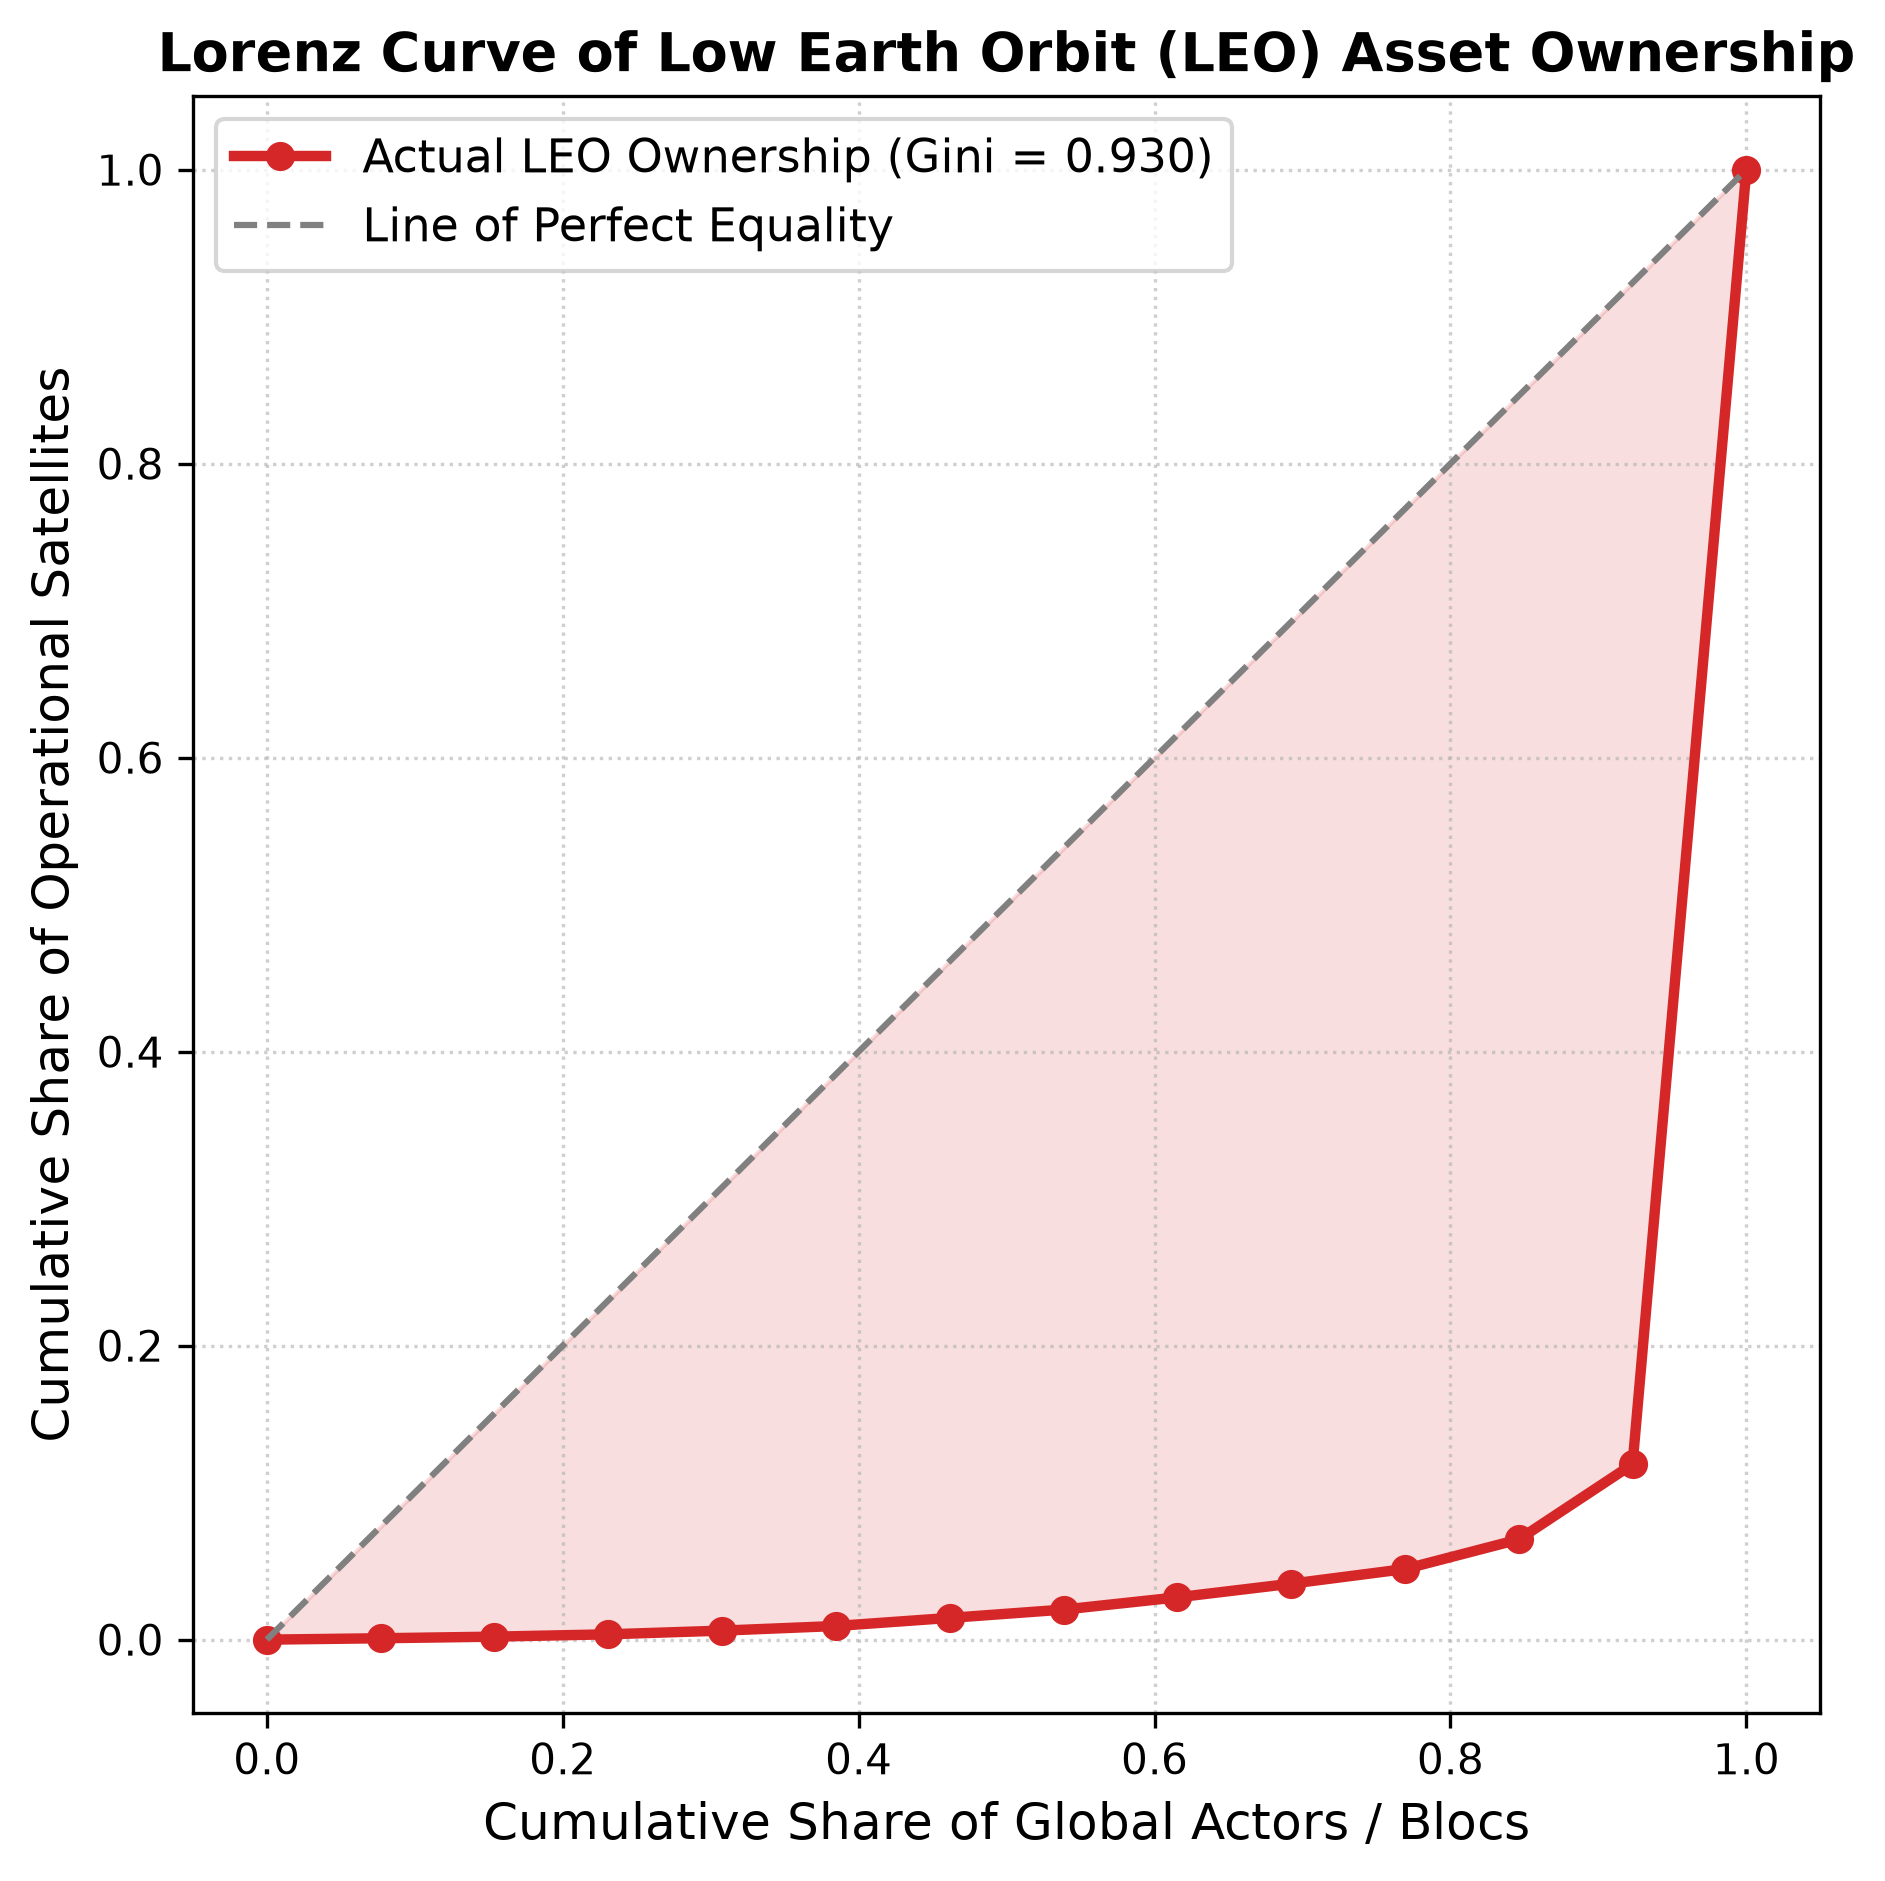

In [7]:
fig_path = "../output/figures/orbital_inequality_lorenz.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 5. 30-Day Vectorized SGP4 Orbit Propagation & Regional Dwell
We simulate the trajectories of a representative fleet of operational satellites over a 30-day period (720 hourly time steps, totaling over 2.67 million spatial state evaluations) using C++ vectorized `SatrecArray`.


In [8]:
regional_df = pd.read_csv("../data/processed/regional_dwell_statistics.csv")
if "Unnamed: 0" in regional_df.columns:
    regional_df = regional_df.rename(columns={"Unnamed: 0": "Region"})
display(regional_df[["Region", "category", "area_mkm2", "dwell_hours", "dwell_density_hours_per_mkm2"]])


,Region,category,area_mkm2,dwell_hours,dwell_density_hours_per_mkm2
0,North America,Global North,24.709,212928.0,8617.426849
1,Western Europe,Global North,5.400,55602.0,10296.666667
2,Eastern Europe & Russia,Eurasia,18.000,132420.0,7356.666667
3,East Asia,Asia-Pacific,11.800,126503.0,10720.593220
4,South Asia,Global South,5.100,52207.0,10236.666667
5,Middle East & North Africa (MENA),Global South,11.100,107803.0,9711.981982
6,Sub-Saharan Africa,Global South,24.300,243825.0,10033.950617
7,Latin America & Caribbean,Global South,20.100,407947.0,20295.870647
8,Oceania & Pacific Islands,Global South / Allied,8.500,195593.0,23010.941176
9,Polar Regimes,Commons / Strategic,28.000,313956.0,11212.714286


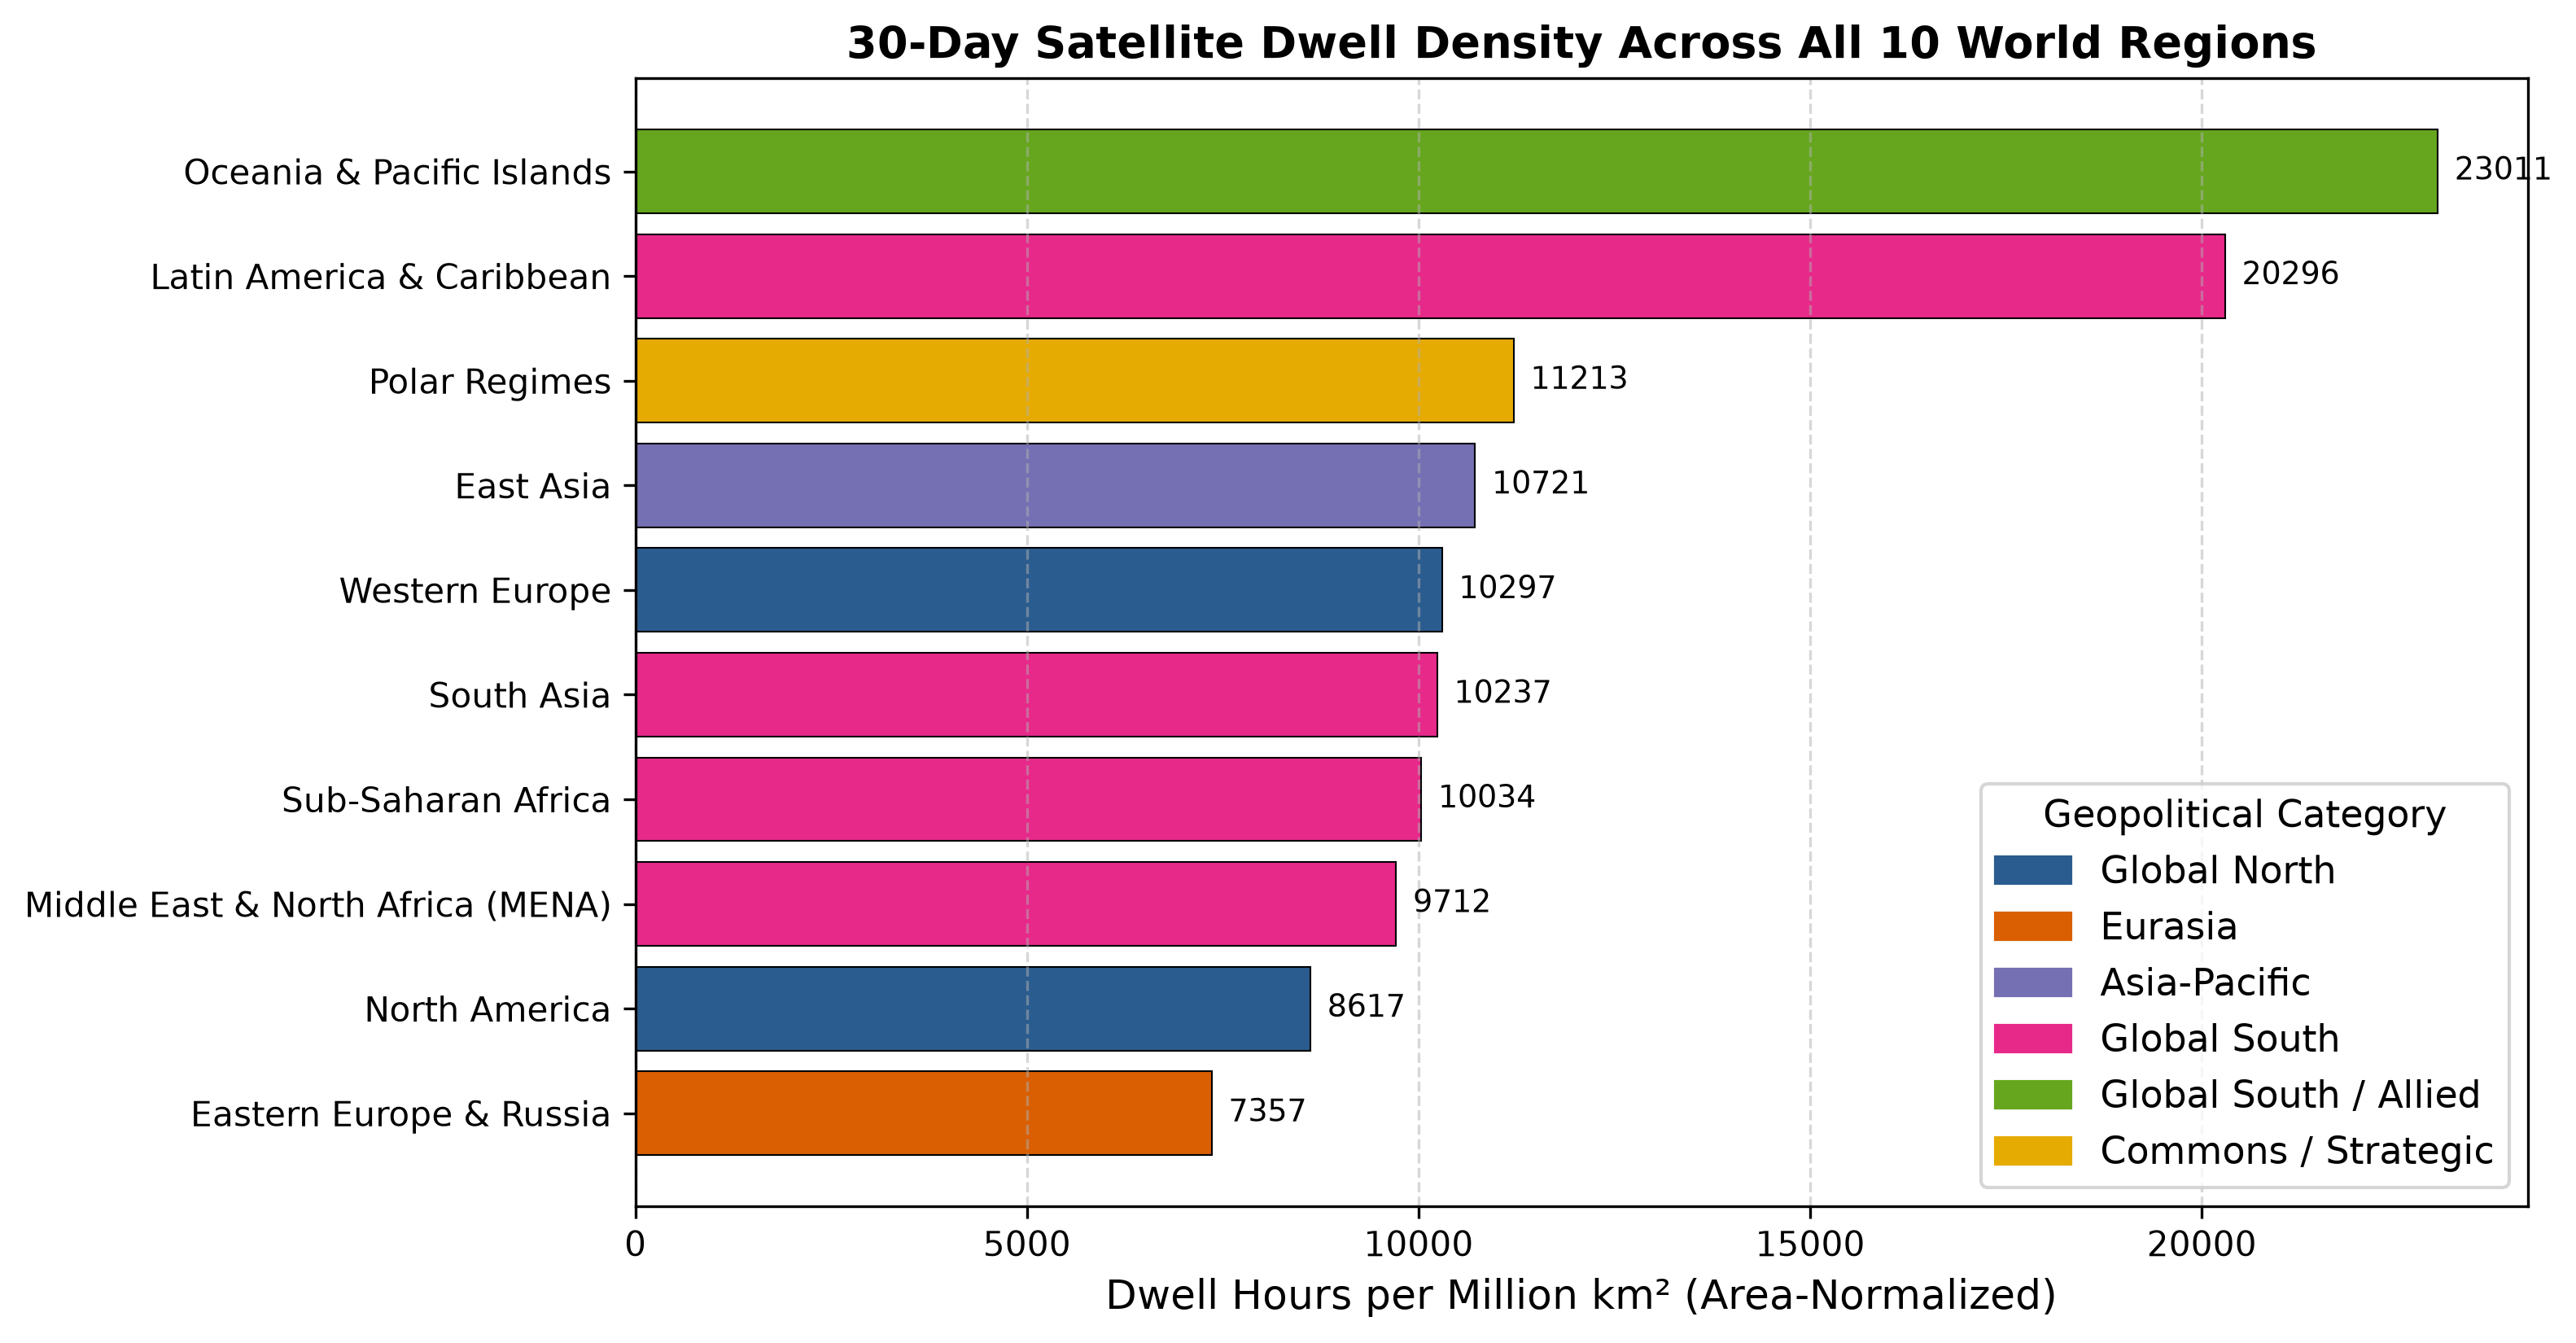

In [9]:
fig_path = "../output/figures/regional_coverage_comparison.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 6. Latitudinal Dwell Skew & Analytical Orbit Mechanics
A circular orbit with inclination $i$ exhibits a ground-track latitude density distribution governed by:
$$\frac{dt}{d\phi} = \frac{1}{\pi \sqrt{\sin^2(i) - \sin^2(\phi)}}$$
This causes satellites to dwell longer at their northern and southern turning points ($\pm i$) than near the equator. For mega-constellations deployed at $i \approx 53^\circ$ (e.g. Starlink), maximum orbital coverage is concentrated over $45^\circ\text{--}53^\circ\text{N}$ (North America, Europe, East Asia).


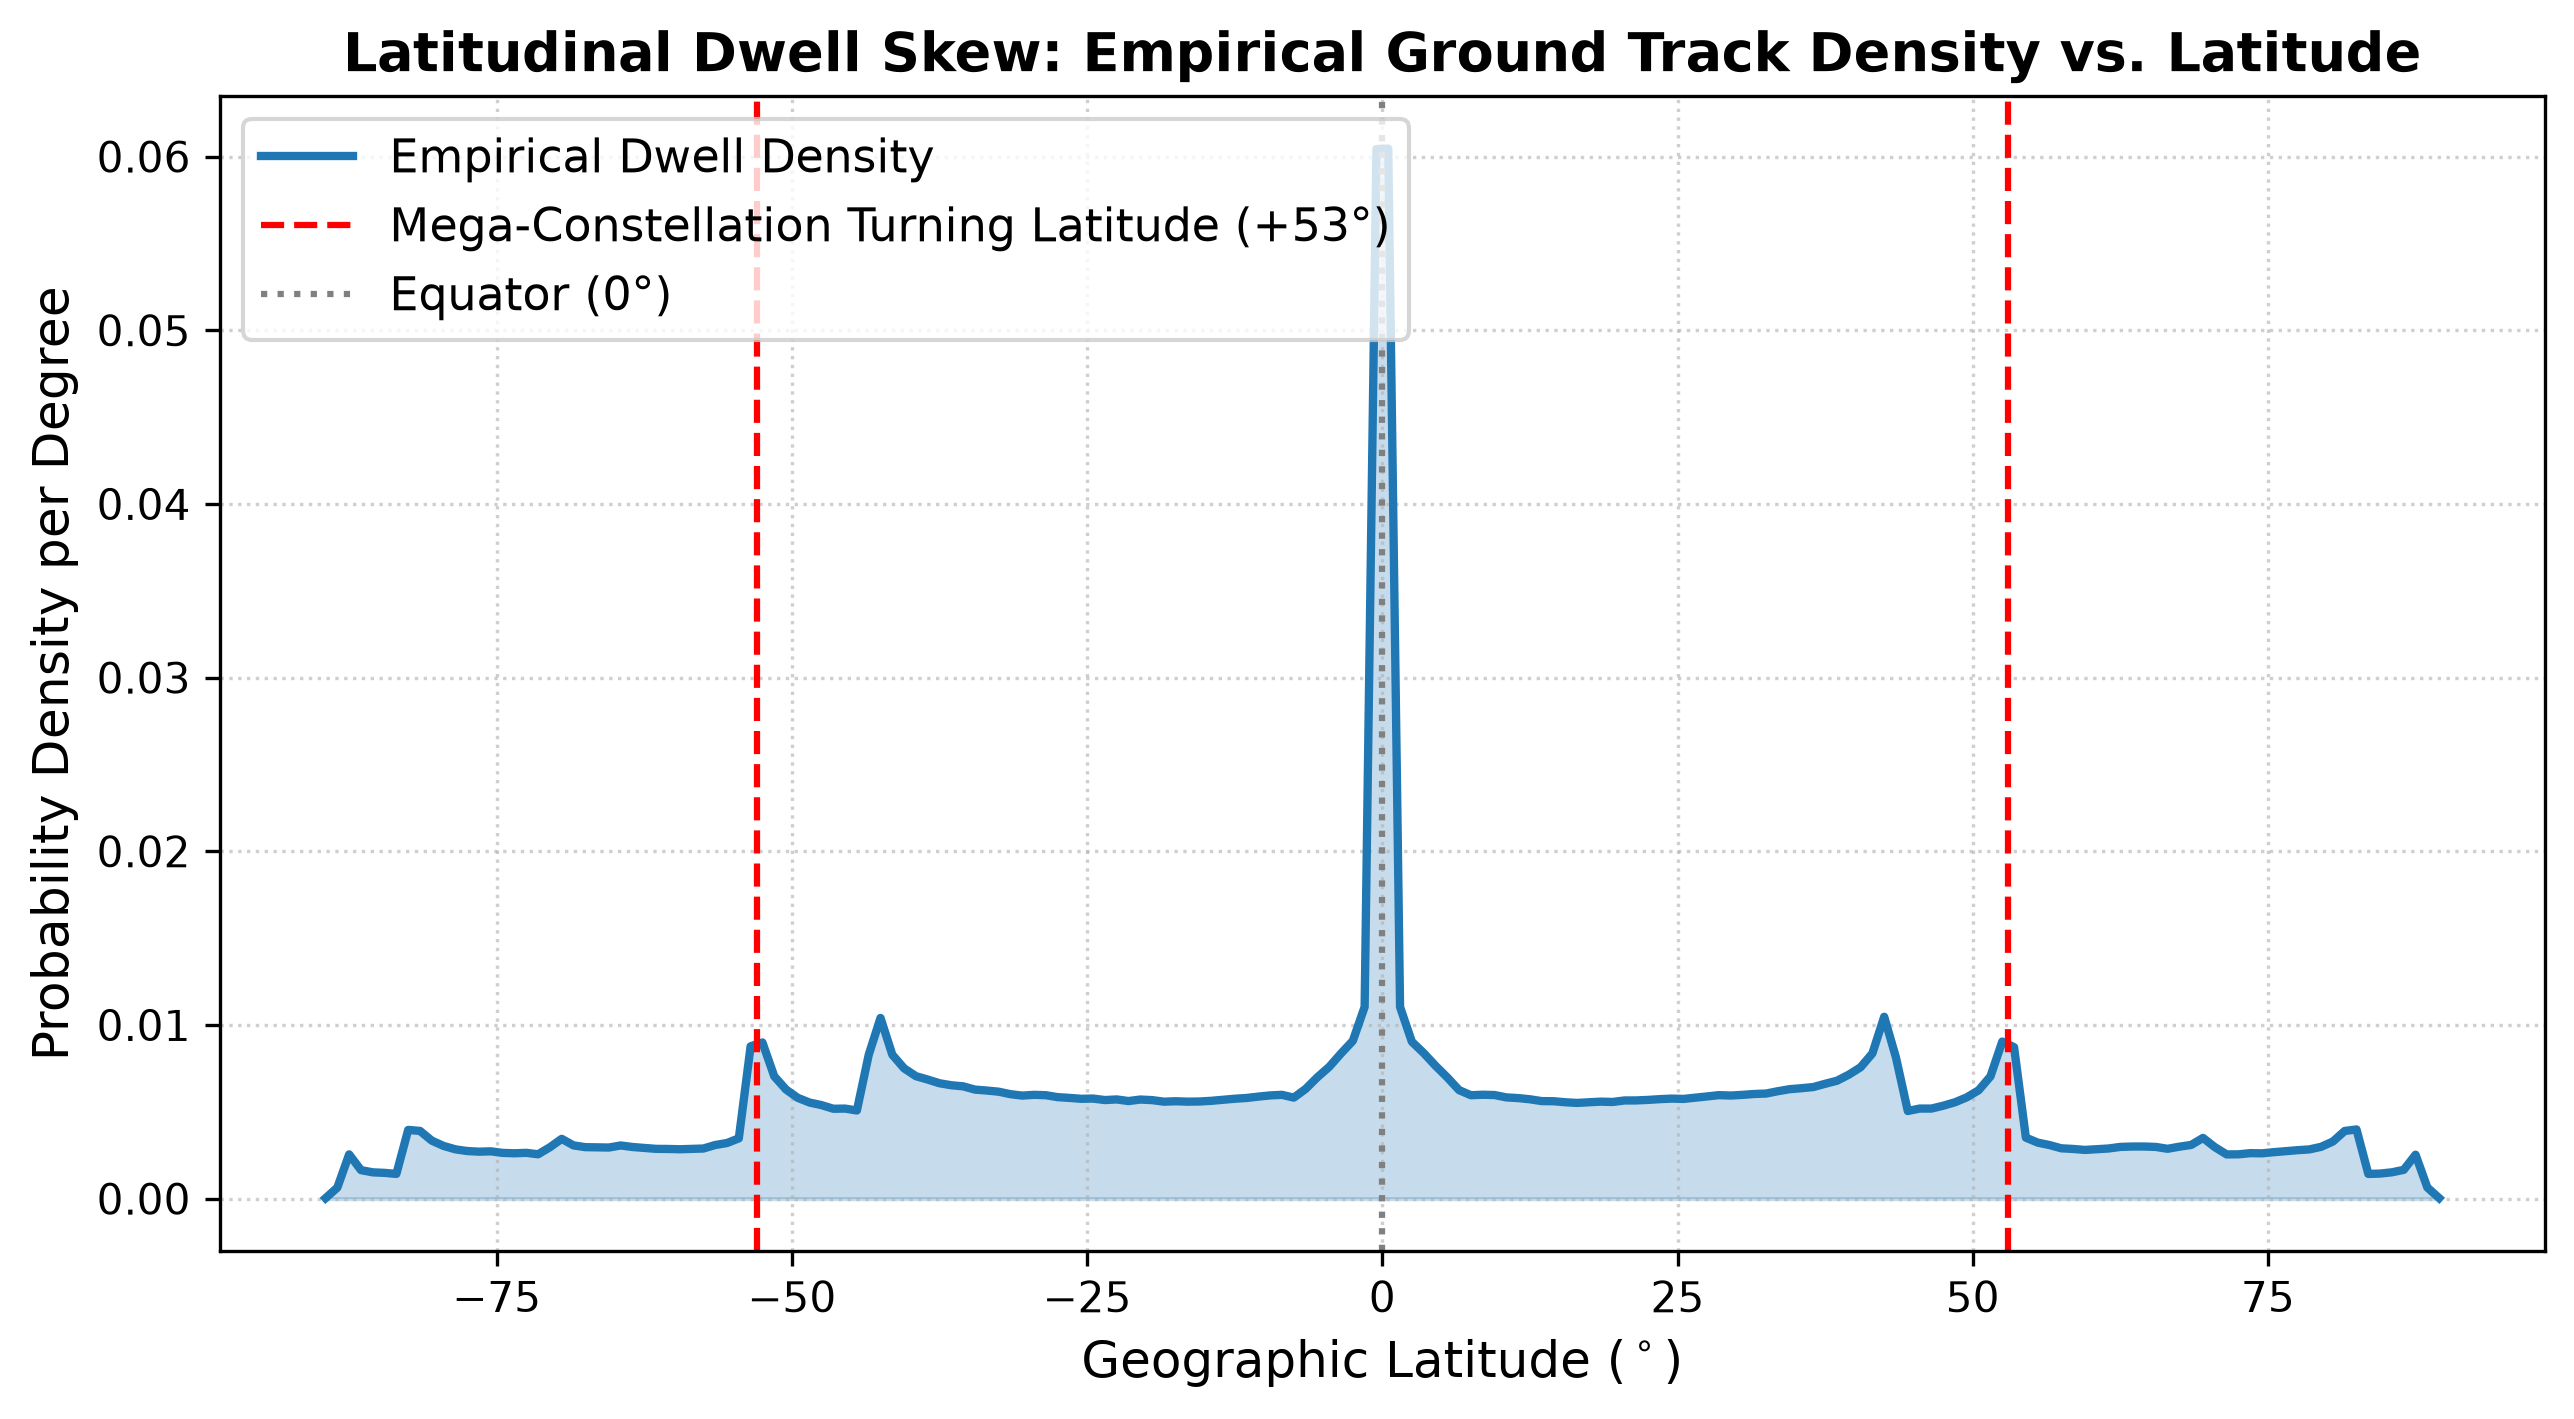

In [10]:
fig_path = "../output/figures/latitudinal_dwell_profile.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 7. Global Satellite Activity Heatmap (Entire World)
High-contrast, high-resolution 2D heatmap showing satellite activity across the entire globe over the 30-day simulation window. Turning latitudes ($\pm 53^\circ$ for Starlink, $\pm 88^\circ$ for OneWeb) and the equator ($0^\circ$) are highlighted.


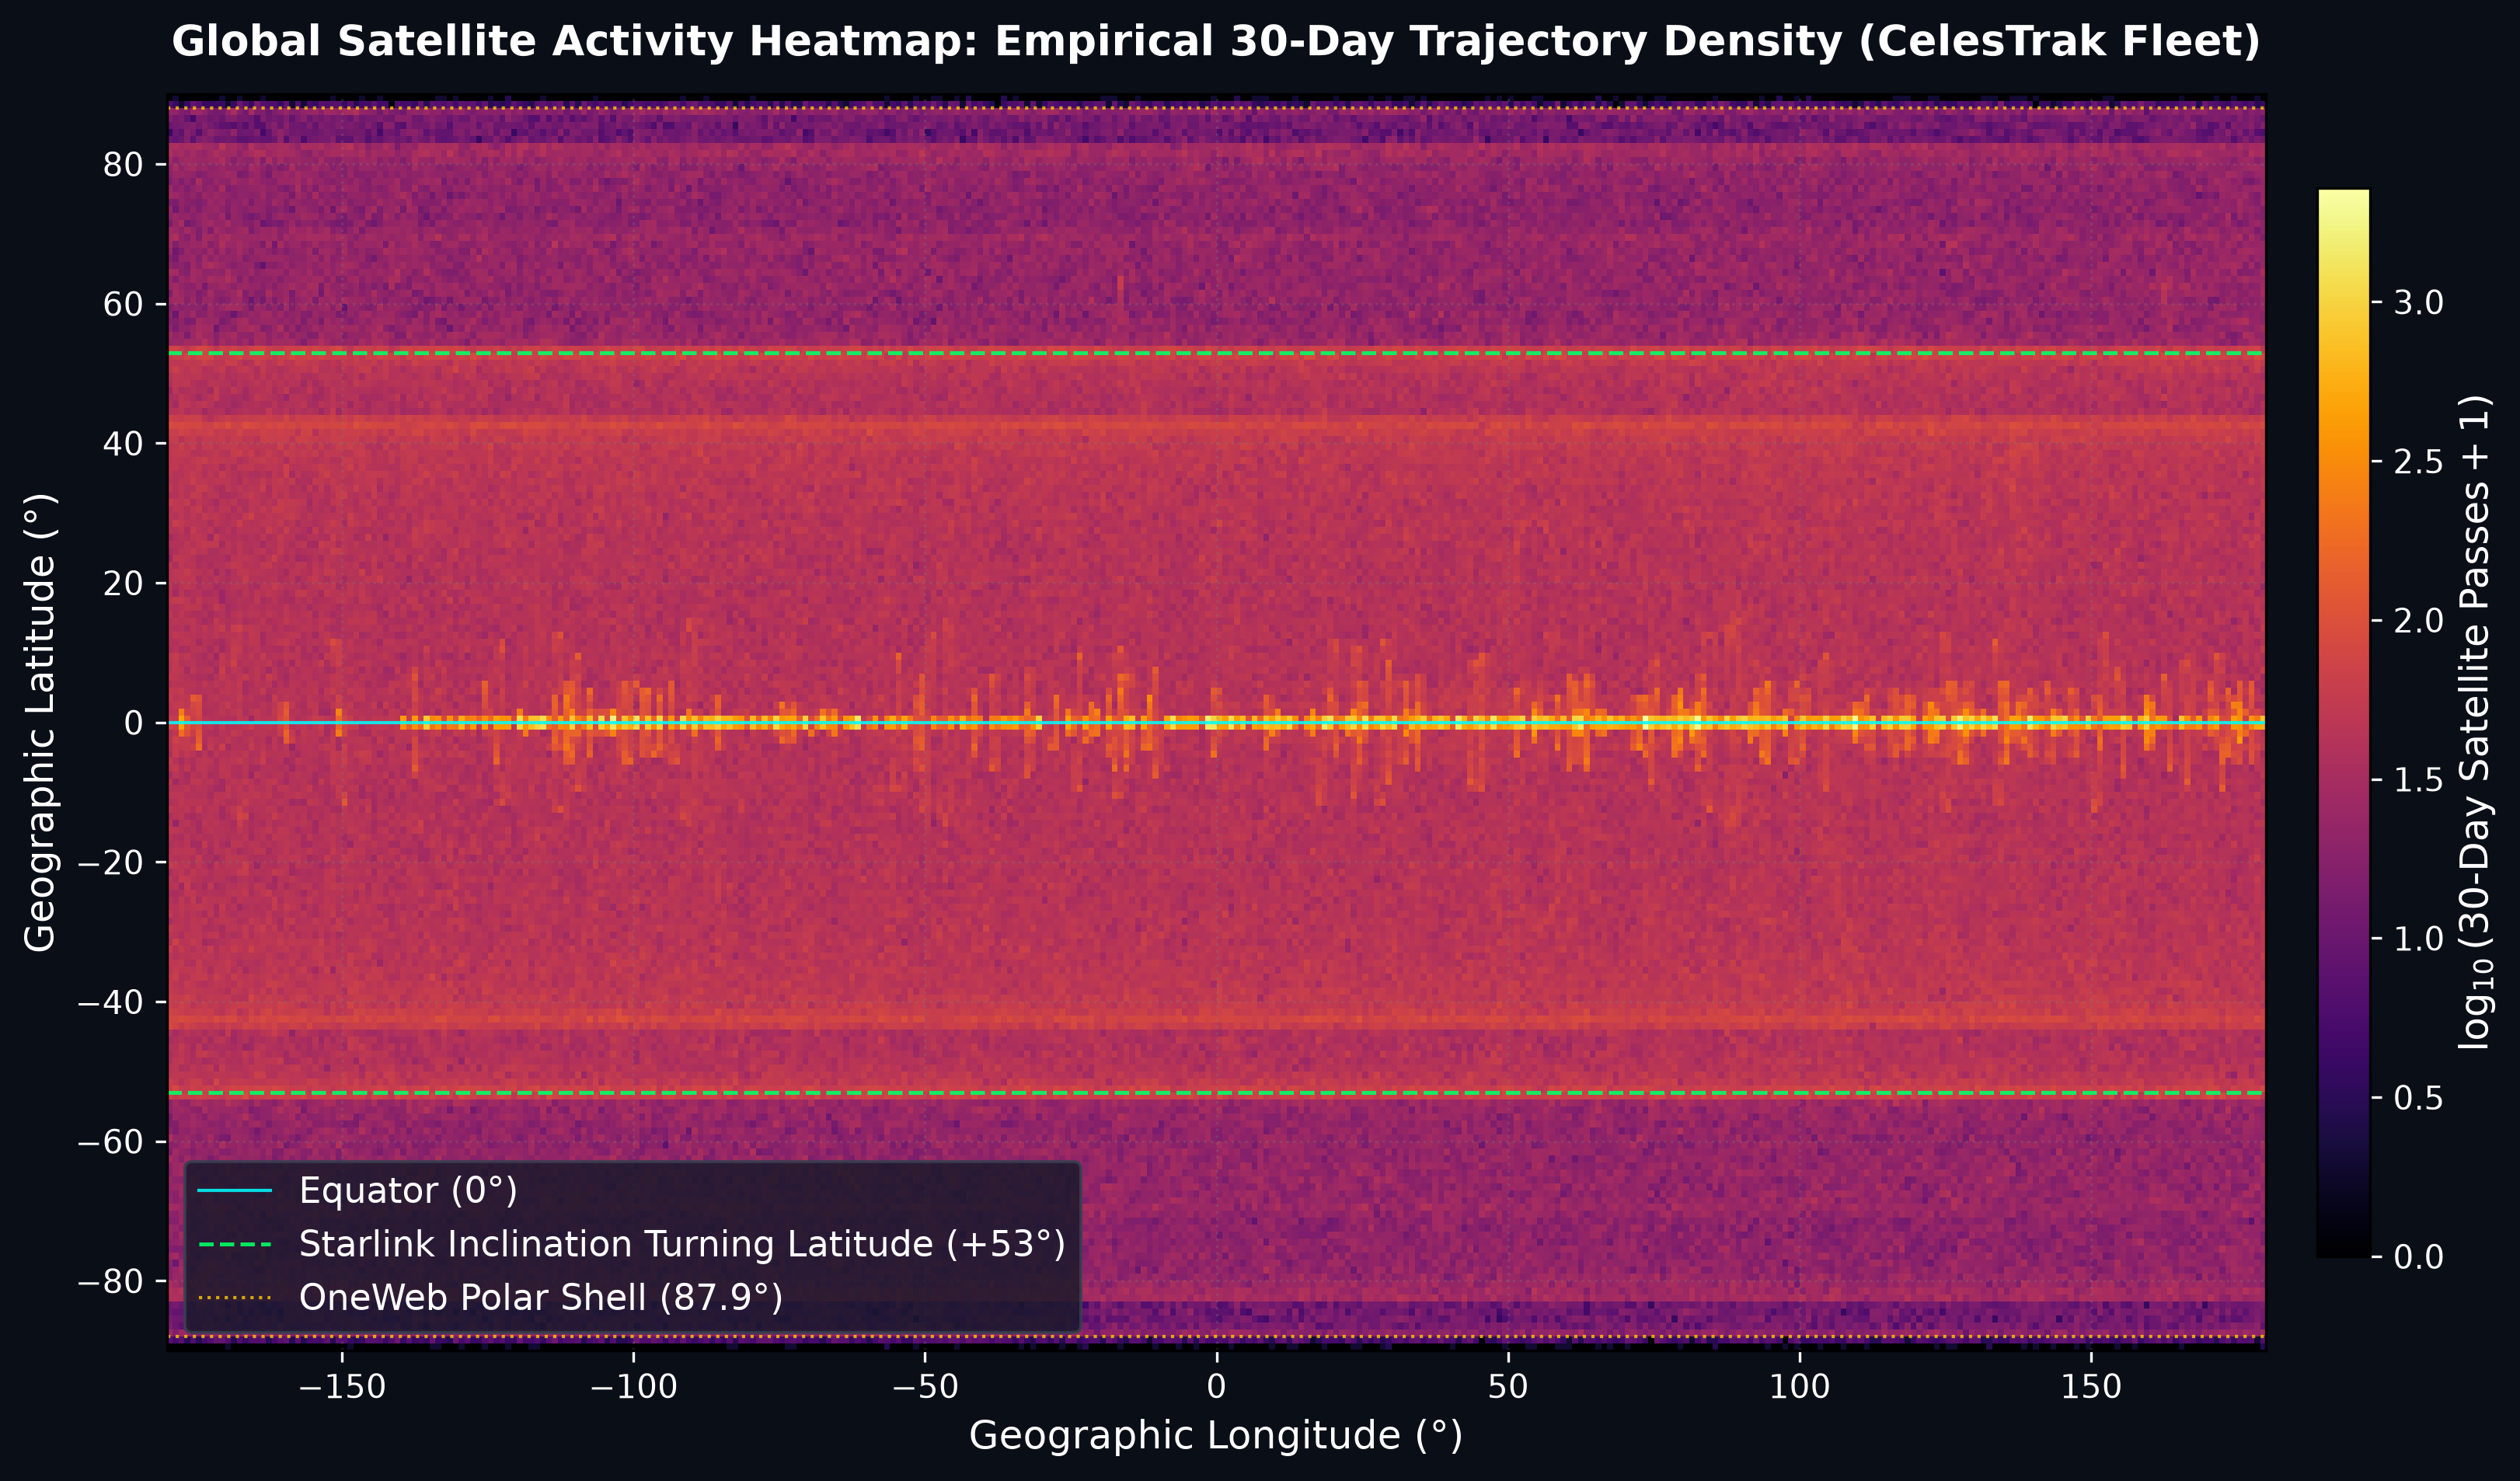

In [11]:
fig_path = "../output/figures/world_satellite_activity_heatmap.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 8. Earth Observation Revisit Disparity Across World Regions
We analyze the revisit interval (hours between satellite passes) for remote sensing and reconnaissance platforms over all 10 world regions.


In [12]:
eo_revisit_df = pd.read_csv("../data/processed/earth_observation_revisit.csv")
display(eo_revisit_df)


,Region,Category,Area (M km²),Total EO Passes,Pass Density (Passes / M km²),Estimated Revisit (Hours / M km²)
0,Polar Regimes,Commons / Strategic,28.00,82601,2950.04,0.2
1,Oceania & Pacific Islands,Global South / Allied,8.50,21876,2573.65,0.3
2,Latin America & Caribbean,Global South,20.10,47810,2378.61,0.3
3,Western Europe,Global North,5.40,8587,1590.19,0.5
4,South Asia,Global South,5.10,7291,1429.61,0.5
5,Eastern Europe & Russia,Eurasia,18.00,24770,1376.11,0.5
6,Middle East & North Africa (MENA),Global South,11.10,15081,1358.65,0.5
7,East Asia,Asia-Pacific,11.80,15799,1338.90,0.5
8,North America,Global North,24.71,32585,1318.75,0.5
9,Sub-Saharan Africa,Global South,24.30,26451,1088.52,0.7


## 9. Space Debris Liability Index: Environmental Injustice in Orbit
We examine the ratio of tracked orbital debris generated relative to active operational payloads:
$$R_{\text{liability}} = \frac{N_{\text{debris}}}{N_{\text{active\_payloads}}}$$


In [13]:
debris_liability_df = pd.read_csv("../data/processed/debris_liability_index.csv")
display(debris_liability_df.head(10))


,Owner,Active Payloads,Tracked Debris,Total Objects,Debris Liability Ratio
0,UNK,43,2667,2710,62.02
1,CIS,73,1,74,0.01
2,US,11653,0,11653,0.00
3,UK,663,0,663,0.00
4,PRC,465,0,465,0.00
5,JPN,56,0,56,0.00
6,IND,51,0,51,0.00
7,ESA,47,0,47,0.00
8,SES,36,0,36,0.00
9,ITSO,36,0,36,0.00


## 10. The 2019 "Enclosure Inflection Point" (1957–2026)
We track the historical accumulation of active operational satellites from the launch of Sputnik 1 (1957) to the present day (2026). In 2019, commercial mega-constellations triggered an exponential inflection point that transformed the orbital commons into an enclosed private industrial zone.


In [14]:
temporal_df = pd.read_csv("../data/processed/temporal_enclosure_cumulative.csv")
display(temporal_df.tail(10))


,LAUNCH_YEAR,China (PRC),China Commercial (Qianfan),Europe (ESA / EU),Europe / UK Commercial (OneWeb),Global South,India (ISRO),Japan (JAXA),Other / International,Russia,US Allied Partners,US Commercial (Planet Labs),US Commercial (SpaceX),US Commercial (Spire),United States (Civil / Defense)
27,2017,65,0,29,0,16,31,23,249,34,6,13,0,8,129
28,2018,92,0,35,0,19,37,24,267,38,6,14,0,8,135
29,2019,109,0,37,6,19,41,25,280,44,6,14,11,8,140
30,2020,115,0,40,108,19,44,28,286,48,6,14,171,8,146
31,2021,132,0,42,390,19,44,29,297,52,6,14,729,9,151
32,2022,142,0,42,499,19,46,30,315,55,6,14,2155,9,159
33,2023,172,0,45,631,19,47,31,324,59,6,20,3941,14,167
34,2024,185,54,54,651,20,49,38,337,63,7,44,5795,25,184
35,2025,206,108,68,651,26,51,47,354,68,7,111,8934,63,216
36,2026,209,256,77,651,26,51,56,365,73,7,127,11204,70,252


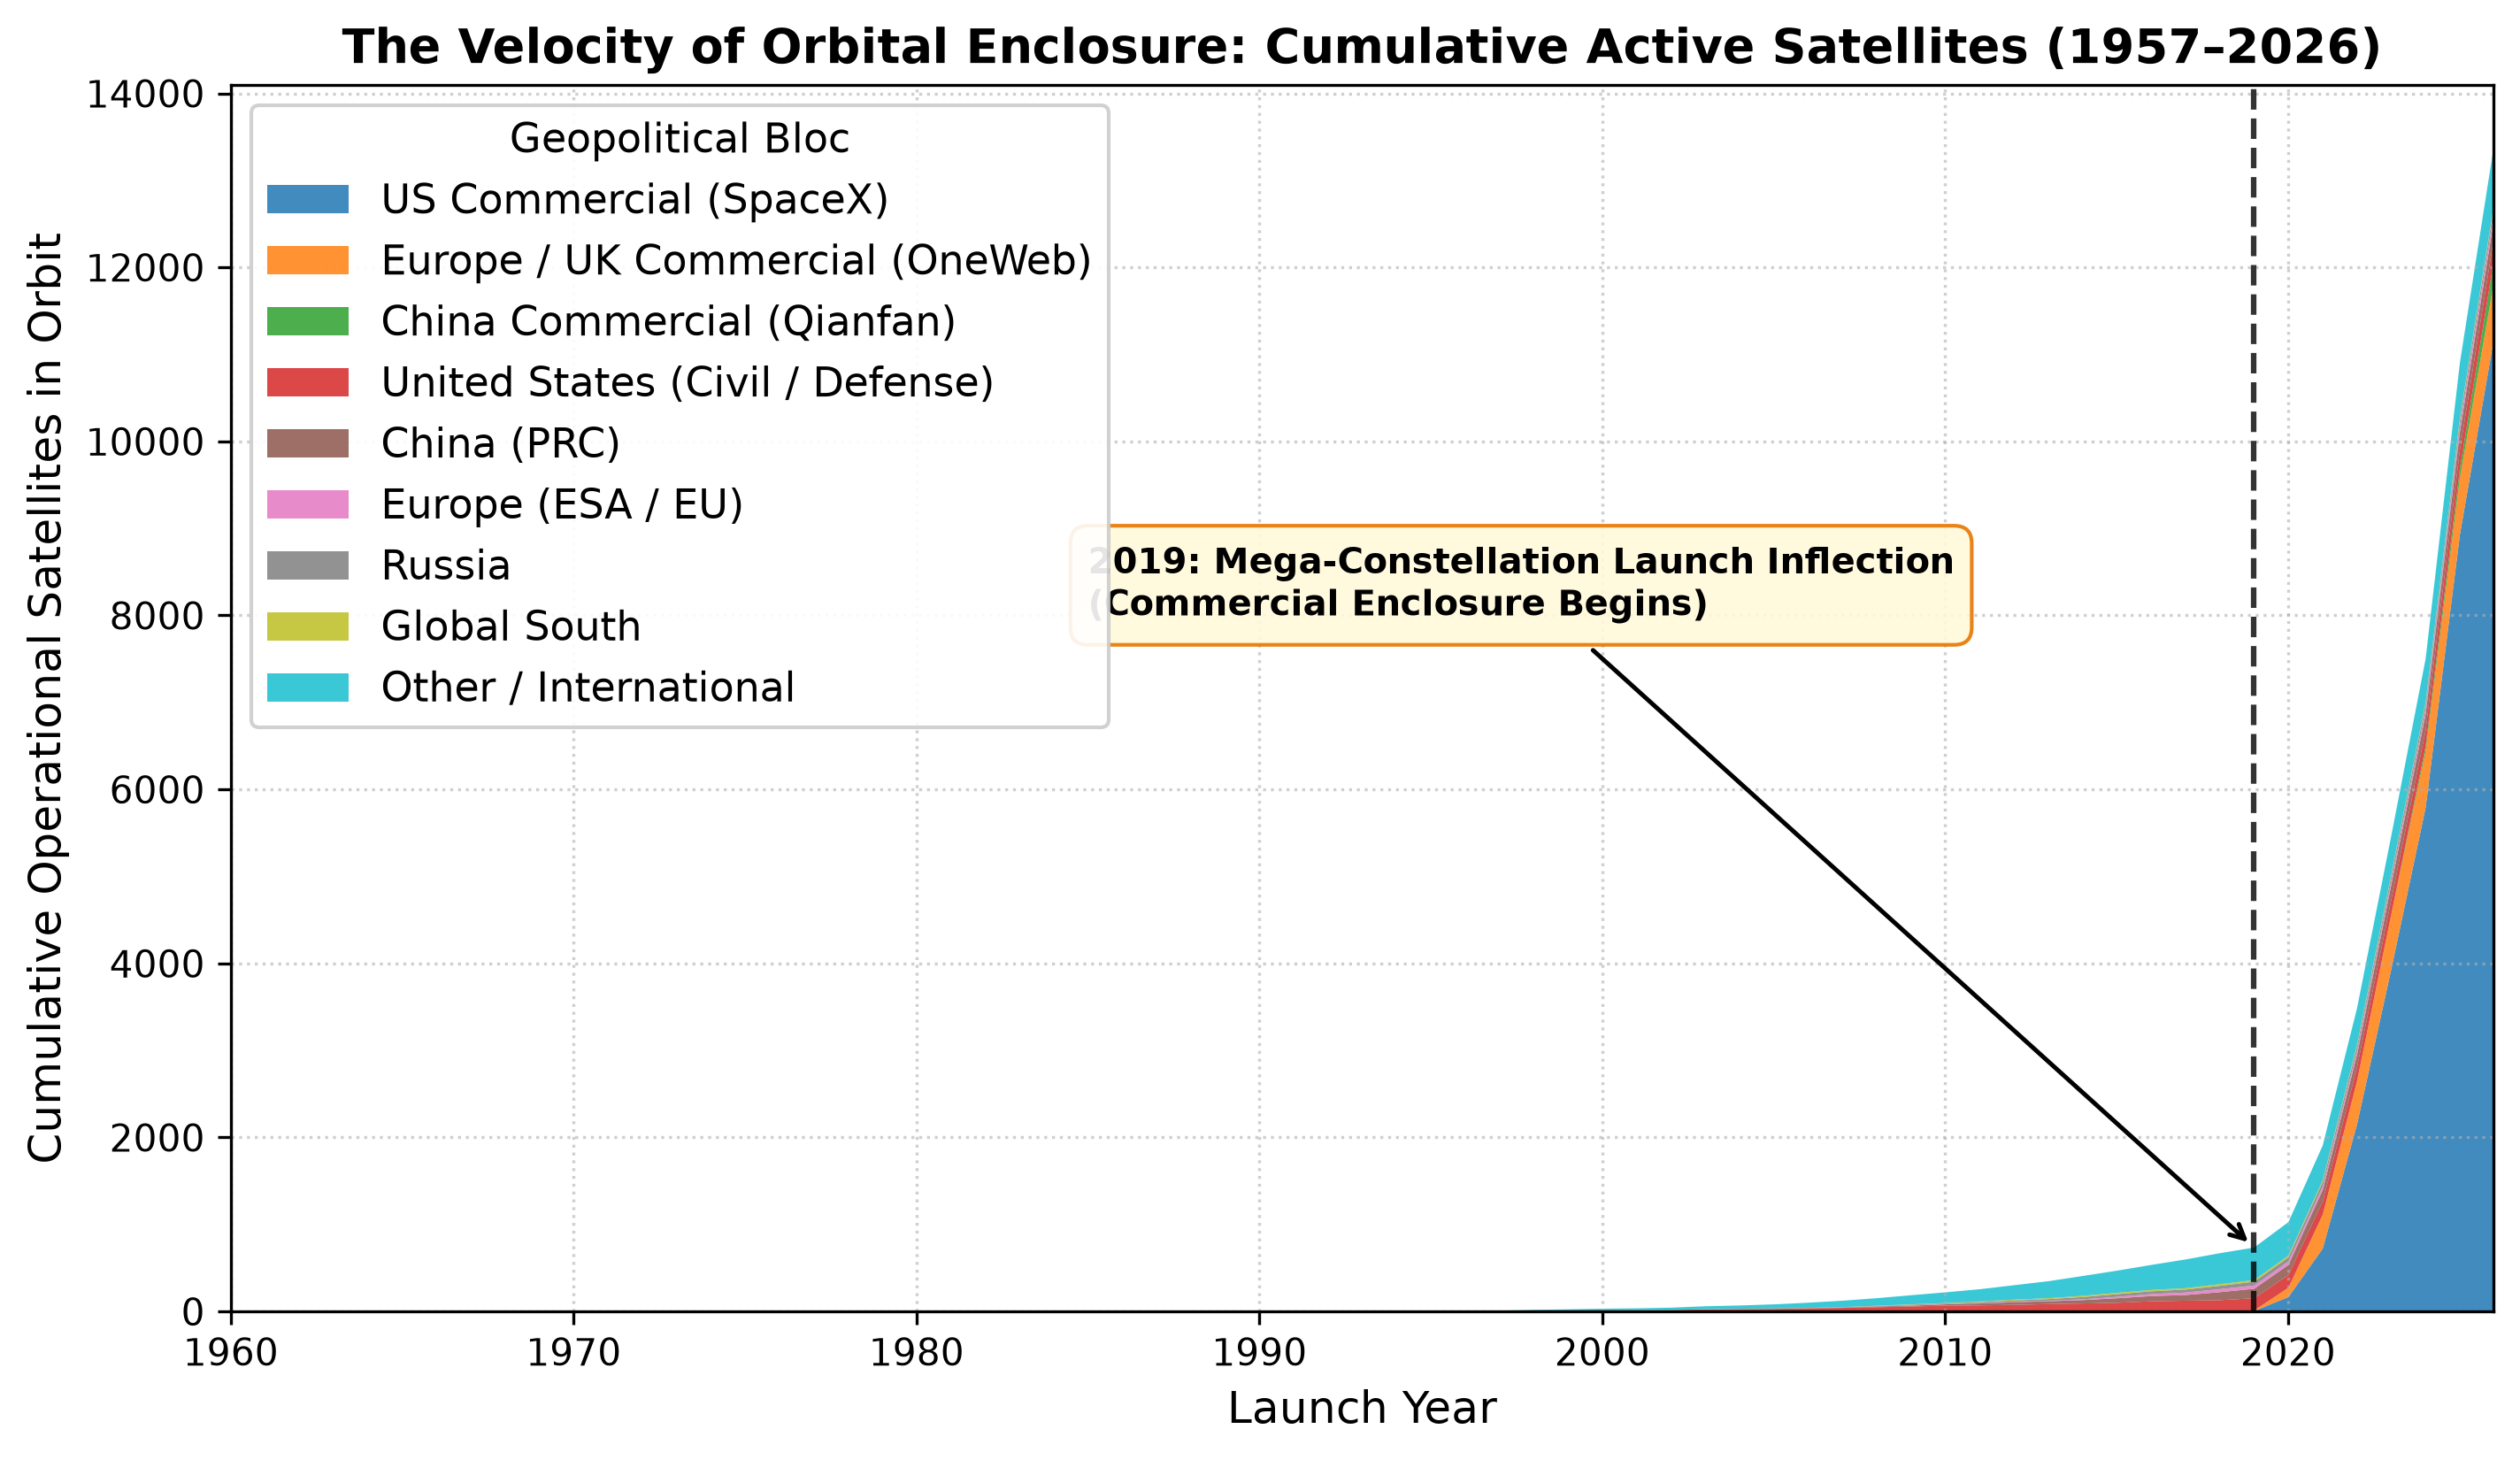

In [15]:
fig_path = "../output/figures/temporal_enclosure_velocity.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 11. Volumetric Spatial Density: The 550 km Congestion Wall
By dividing the number of satellites in each 25 km altitude shell by the physical spherical shell volume:
$$V(r_1, r_2) = \frac{4}{3}\pi (r_2^3 - r_1^3)$$
we calculate the spatial density in objects per million cubic kilometers ($N / 10^6 \text{ km}^3$).


In [16]:
volumetric_df = pd.read_csv("../data/processed/volumetric_density_profile.csv")
peak_shell = volumetric_df.loc[volumetric_df["Density_Total_per_Mkm3"].idxmax()]
print(f"Peak Congestion Shell: {peak_shell['Altitude_Min_km']}-{peak_shell['Altitude_Max_km']} km")
print(f"Peak Total Density: {peak_shell['Density_Total_per_Mkm3']:.2f} satellites / M km³")
print(f"Starlink Share in Peak Shell: {peak_shell['Starlink_Objects']}/{peak_shell['Total_Objects']} ({peak_shell['Starlink_Objects']/peak_shell['Total_Objects']*100:.1f}%)")
display(volumetric_df[(volumetric_df["Altitude_Mid_km"] >= 500) & (volumetric_df["Altitude_Mid_km"] <= 600)])


Peak Congestion Shell: 450.0-475.0 km
Peak Total Density: 0.42 satellites / M km³
Starlink Share in Peak Shell: 6082.0/6137.0 (99.1%)


,Altitude_Min_km,Altitude_Max_km,Altitude_Mid_km,Shell_Volume_Mkm3,Total_Objects,Starlink_Objects,Other_Objects,Density_Total_per_Mkm3,Density_Starlink_per_Mkm3
12,500.0,525.0,512.5,14916.574197,106,29,77,0.007106,0.001944
13,525.0,550.0,537.5,15025.008419,132,105,27,0.008785,0.006988
14,550.0,575.0,562.5,15133.835341,179,118,61,0.011828,0.007797
15,575.0,600.0,587.5,15243.054962,41,0,41,0.002690,0.000000


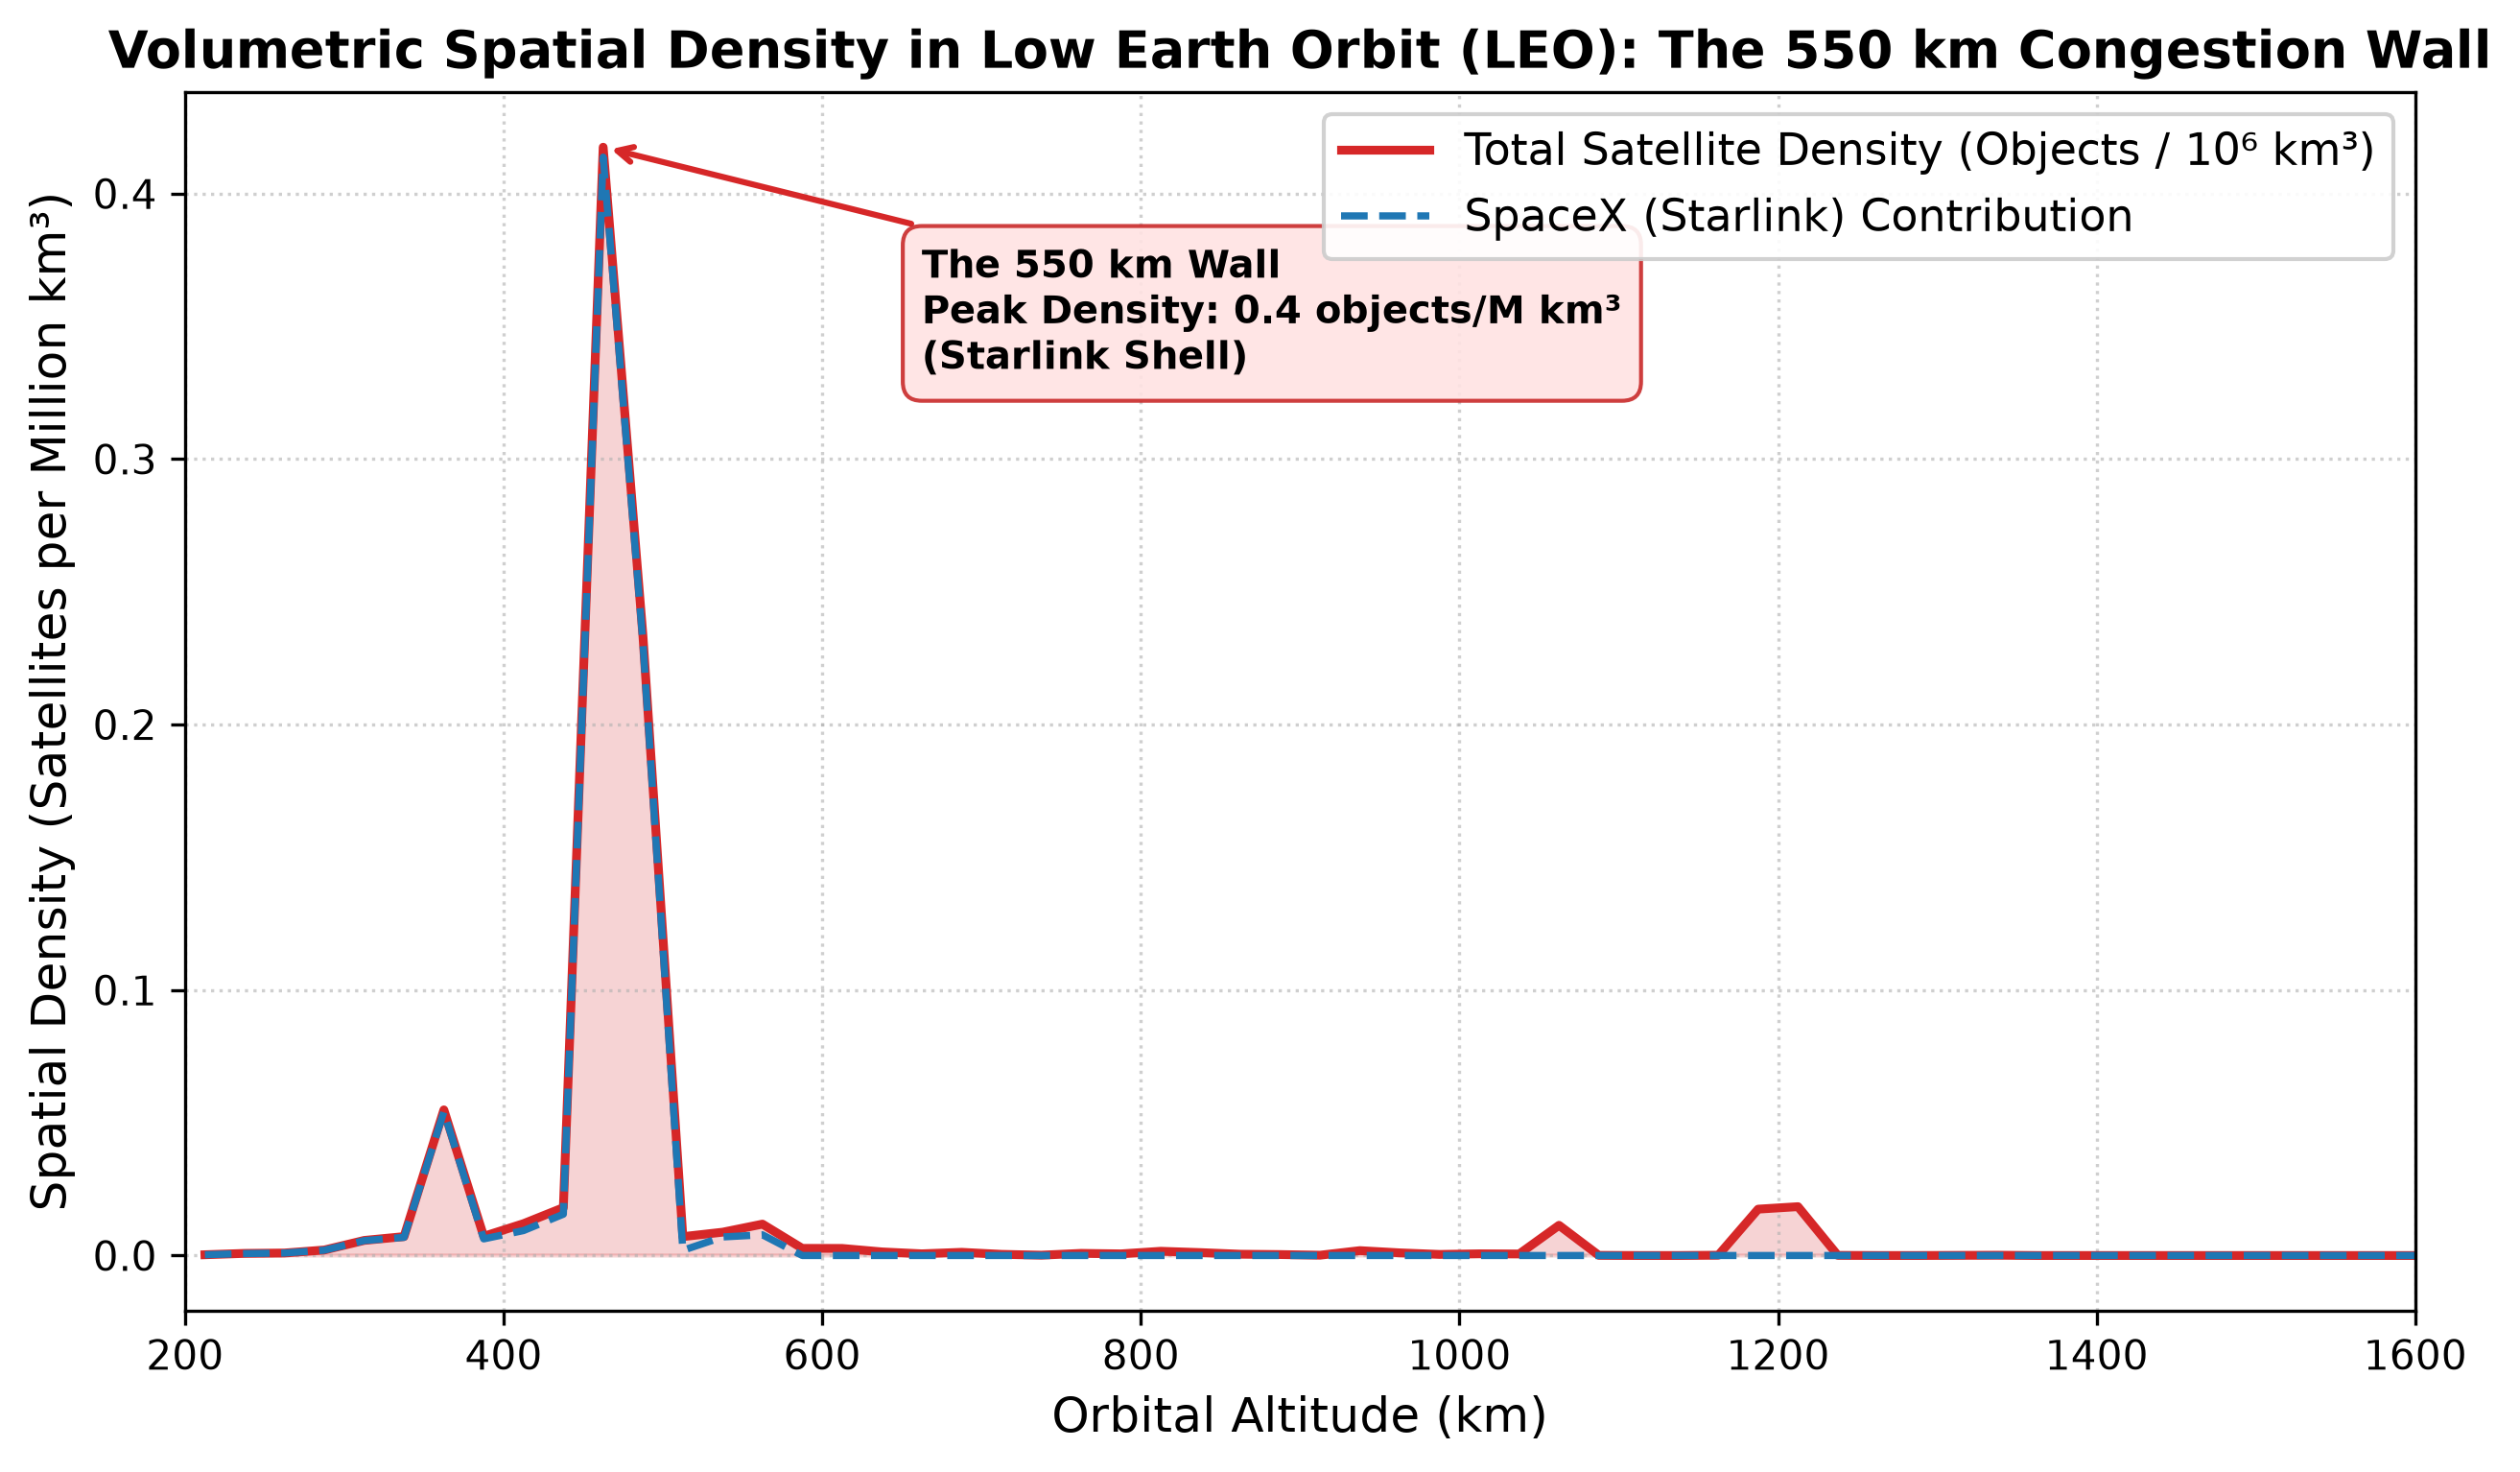

In [17]:
fig_path = "../output/figures/volumetric_orbital_density.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 12. Empirical Test of the 1976 Bogotá Declaration (GEO Longitudinal Sovereignty)
In 1976, eight equatorial nations asserted sovereign rights over the Geostationary Orbit (GEO) segments directly above their territories. We map the longitudes of active geostationary satellites against terrestrial sectors directly below them.


In [18]:
geo_sovereignty_df = pd.read_csv("../data/processed/geo_sovereignty_sectors.csv")
display(geo_sovereignty_df)


,GEO_SECTOR,China (PRC),Europe (ESA / EU),Global South,India (ISRO),Japan (JAXA),Other / International,Russia,US Allied Partners,United States (Civil / Defense)
0,Africa & Europe Corridor,10,0,0,1,0,36,9,0,48
1,Americas & Caribbean,33,1,1,0,12,27,7,6,12
2,East Asia & Southeast Asia,19,4,4,7,4,82,6,0,19
3,Middle East & South Asia,13,0,6,3,3,43,4,1,19
4,Pacific Ocean Commons,15,0,3,16,2,51,5,0,14


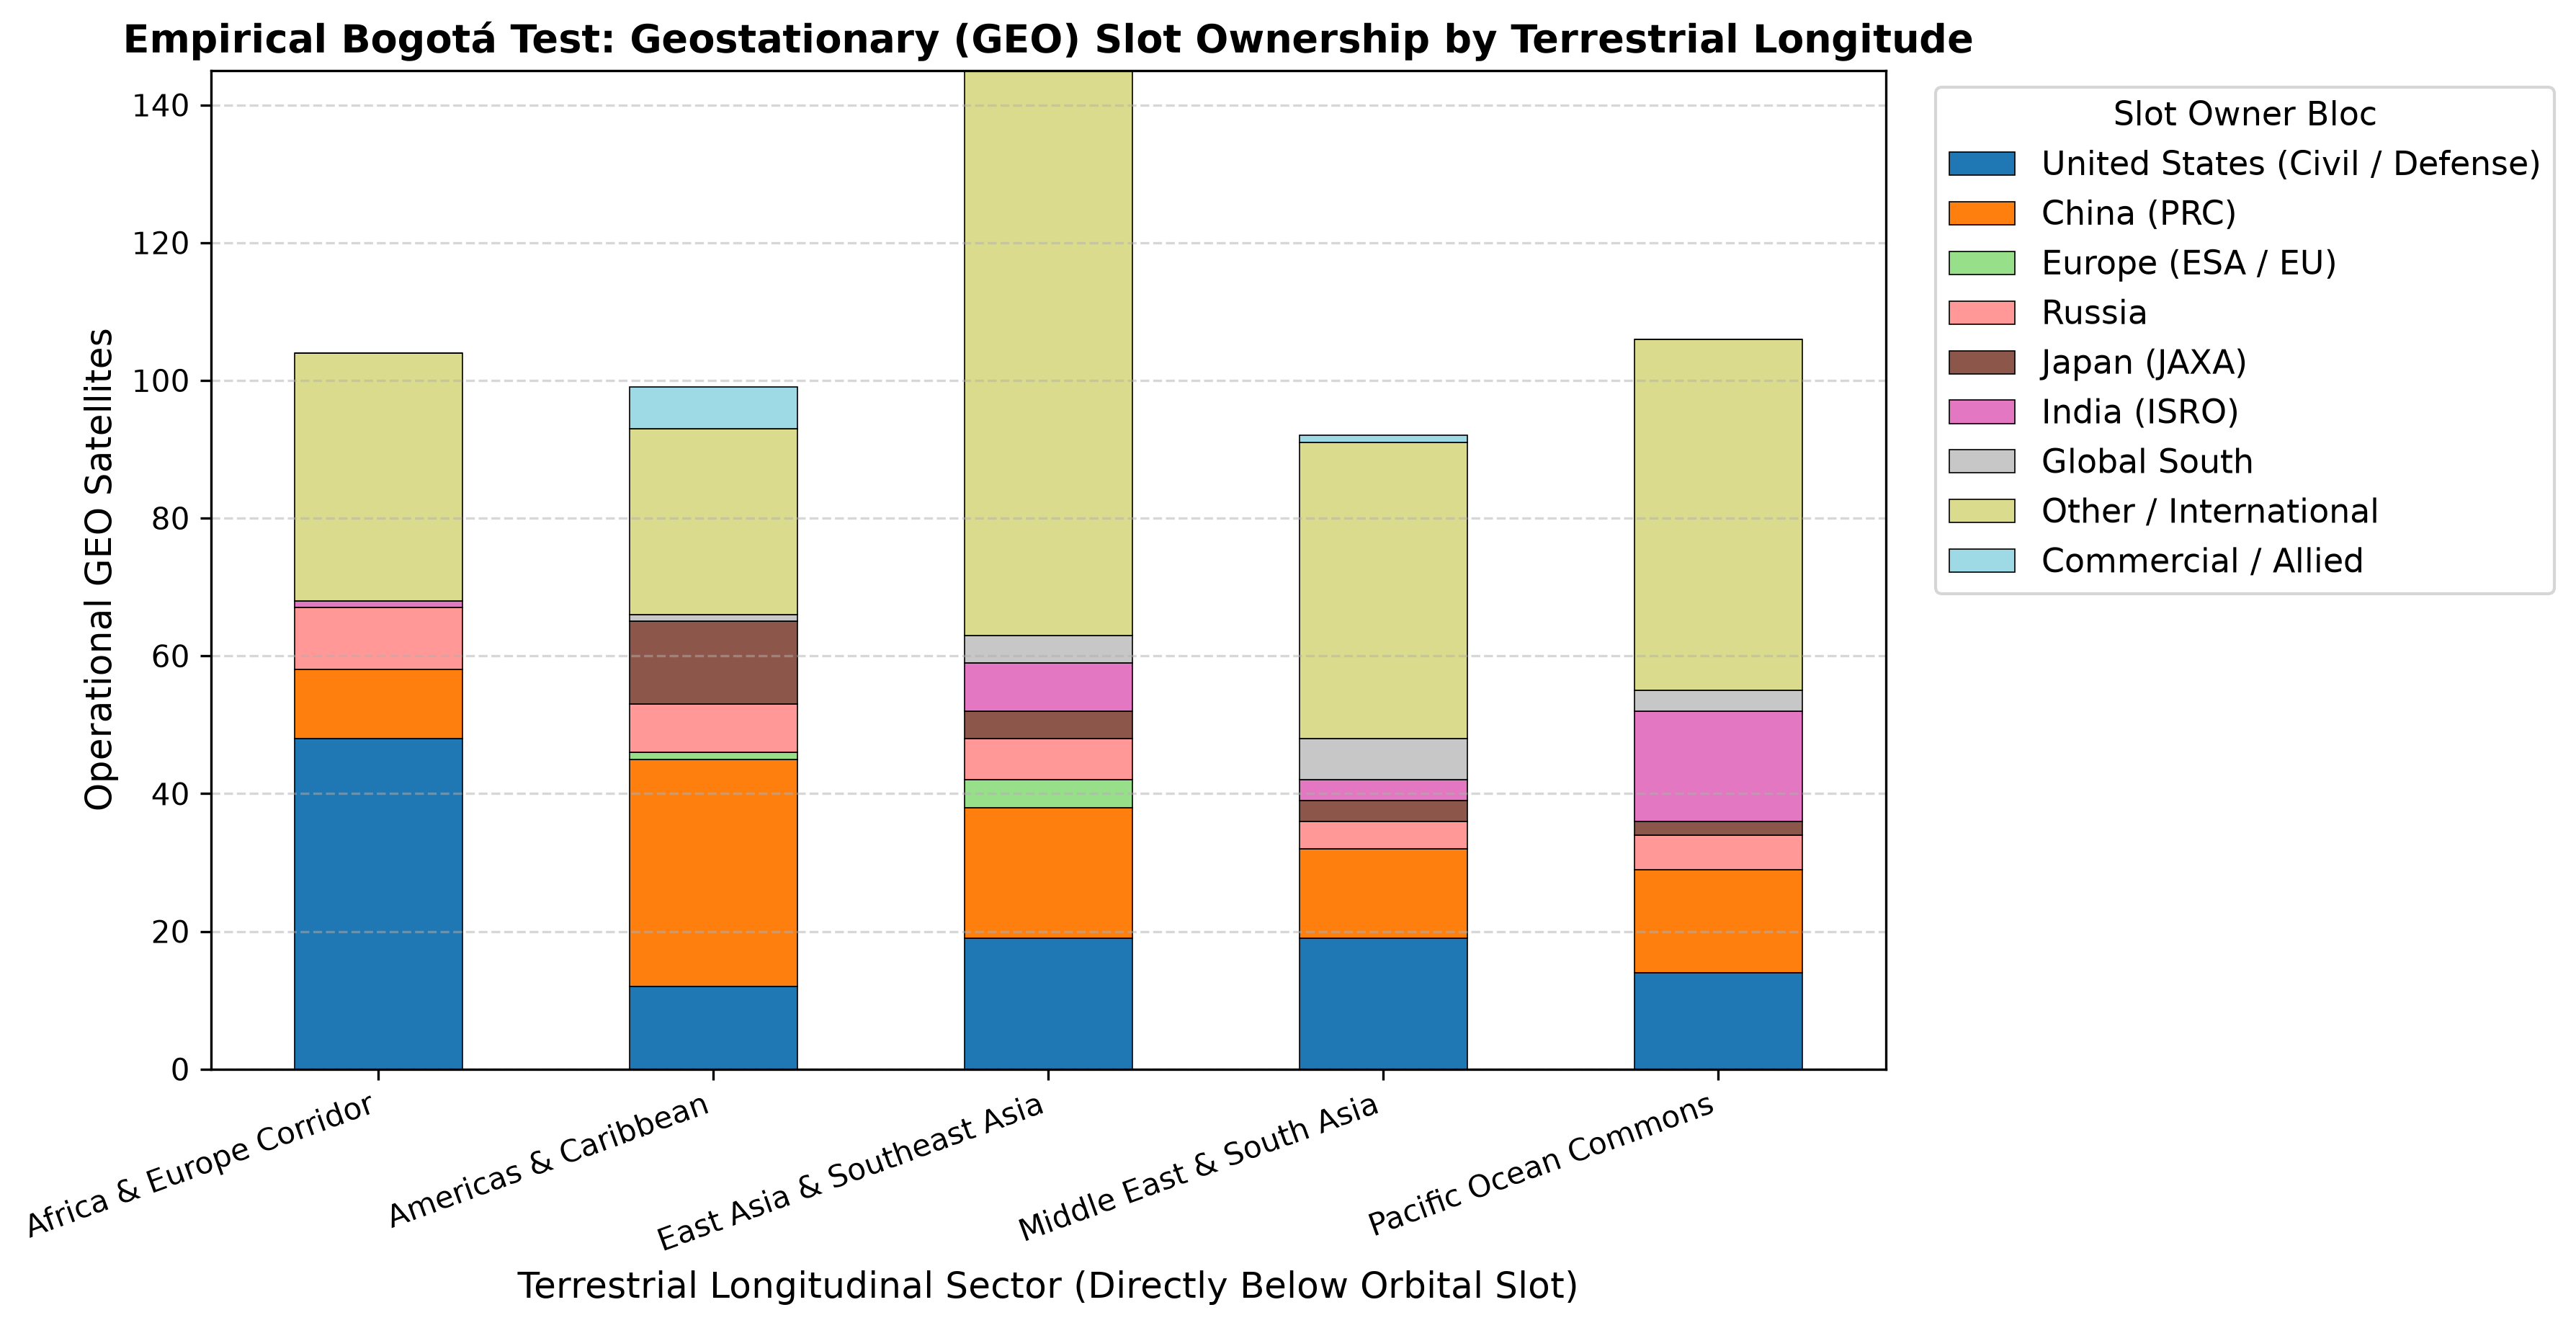

In [19]:
fig_path = "../output/figures/geo_longitudinal_sovereignty.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 13. The Climate-Surveillance Paradox
We contrast regional ND-GAIN Climate Vulnerability Scores against Earth Observation Pass Density. The nations most vulnerable to climate disruption (Sub-Saharan Africa, South Asia, Latin America) have the lowest sovereign spaceborne observation capabilities.


In [20]:
climate_paradox_df = pd.read_csv("../data/processed/climate_vulnerability_gap.csv")
display(climate_paradox_df)


,Region,Category,Climate_Vulnerability_Score,EO_Pass_Density,Estimated_Revisit_Hours,Climate_Surveillance_Disparity_Index
0,Sub-Saharan Africa,Global South,0.58,1088.52,0.7,0.406
1,South Asia,Global South,0.52,1429.61,0.5,0.260
2,Middle East & North Africa (MENA),Global South,0.46,1358.65,0.5,0.230
3,East Asia,Asia-Pacific,0.35,1338.90,0.5,0.175
4,Eastern Europe & Russia,Eurasia,0.32,1376.11,0.5,0.160
5,Oceania & Pacific Islands,Global South / Allied,0.48,2573.65,0.3,0.144
6,North America,Global North,0.27,1318.75,0.5,0.135
7,Latin America & Caribbean,Global South,0.44,2378.61,0.3,0.132
8,Western Europe,Global North,0.25,1590.19,0.5,0.125
9,Polar Regimes,Commons / Strategic,0.50,2950.04,0.2,0.100


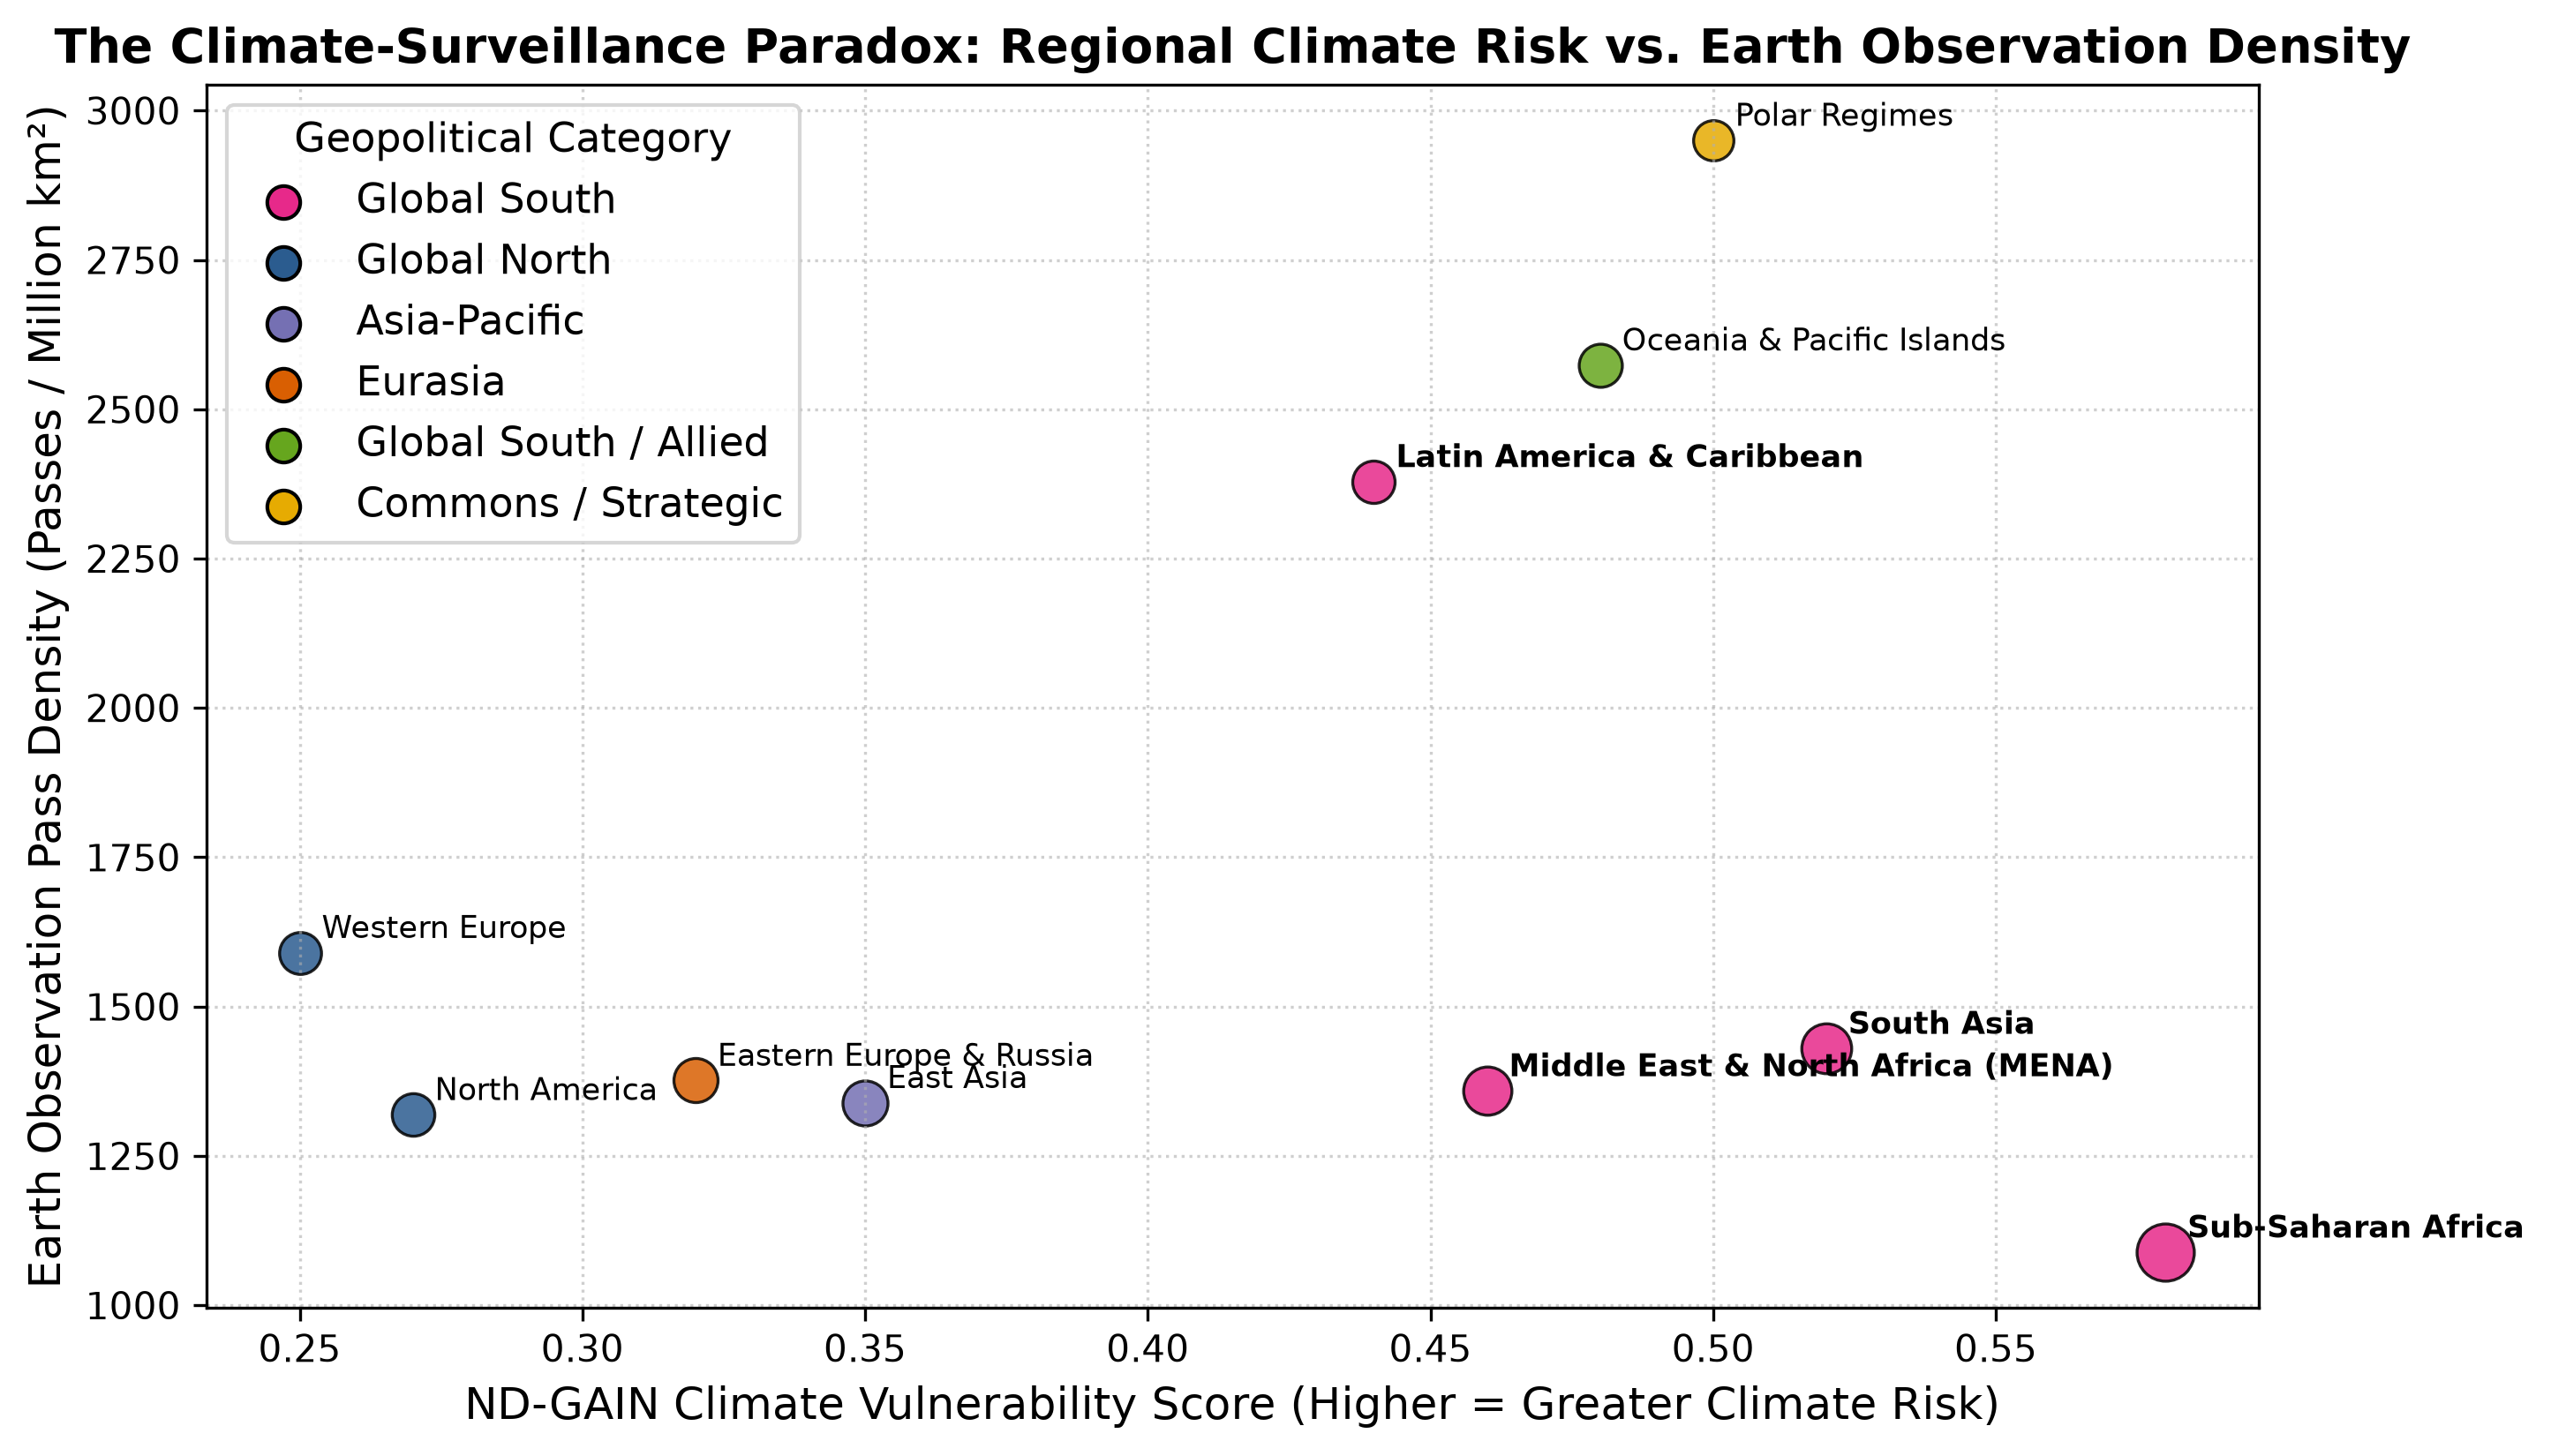

In [21]:
fig_path = "../output/figures/climate_vulnerability_paradox.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 14. Atmospheric Externalities: Megaconstellation Deorbiting & Alumina Deposition
With a 5-year replacement lifespan, mega-constellations deorbit thousands of satellites annually. When satellites burn up in the mesosphere (60–80 km), they vaporize metric tons of aerospace aluminum alloys into aluminum oxide (alumina) nanoparticles, posing significant ozone depletion and radiative forcing risks.


In [22]:
deorbit_mass_df = pd.read_csv("../data/processed/atmospheric_deorbit_deposition.csv")
display(deorbit_mass_df)


,Operator / Constellation,Active Satellites,Avg Dry Mass (kg),Operational Lifespan (Yrs),Annual Satellites Deorbiting,Annual Mass Burn-up (Metric Tons),Annual Alumina Injection (Tons)
0,SpaceX (Starlink),11204,550.0,5.0,2240.8,1232.44,985.95
1,OneWeb,651,150.0,6.0,108.5,16.27,13.02
2,China (Qianfan),256,300.0,5.0,51.2,15.36,12.29
3,Other Commercial LEO,503,200.0,7.0,71.9,14.37,11.50
4,Planet Labs,104,5.0,3.0,34.7,0.17,0.14


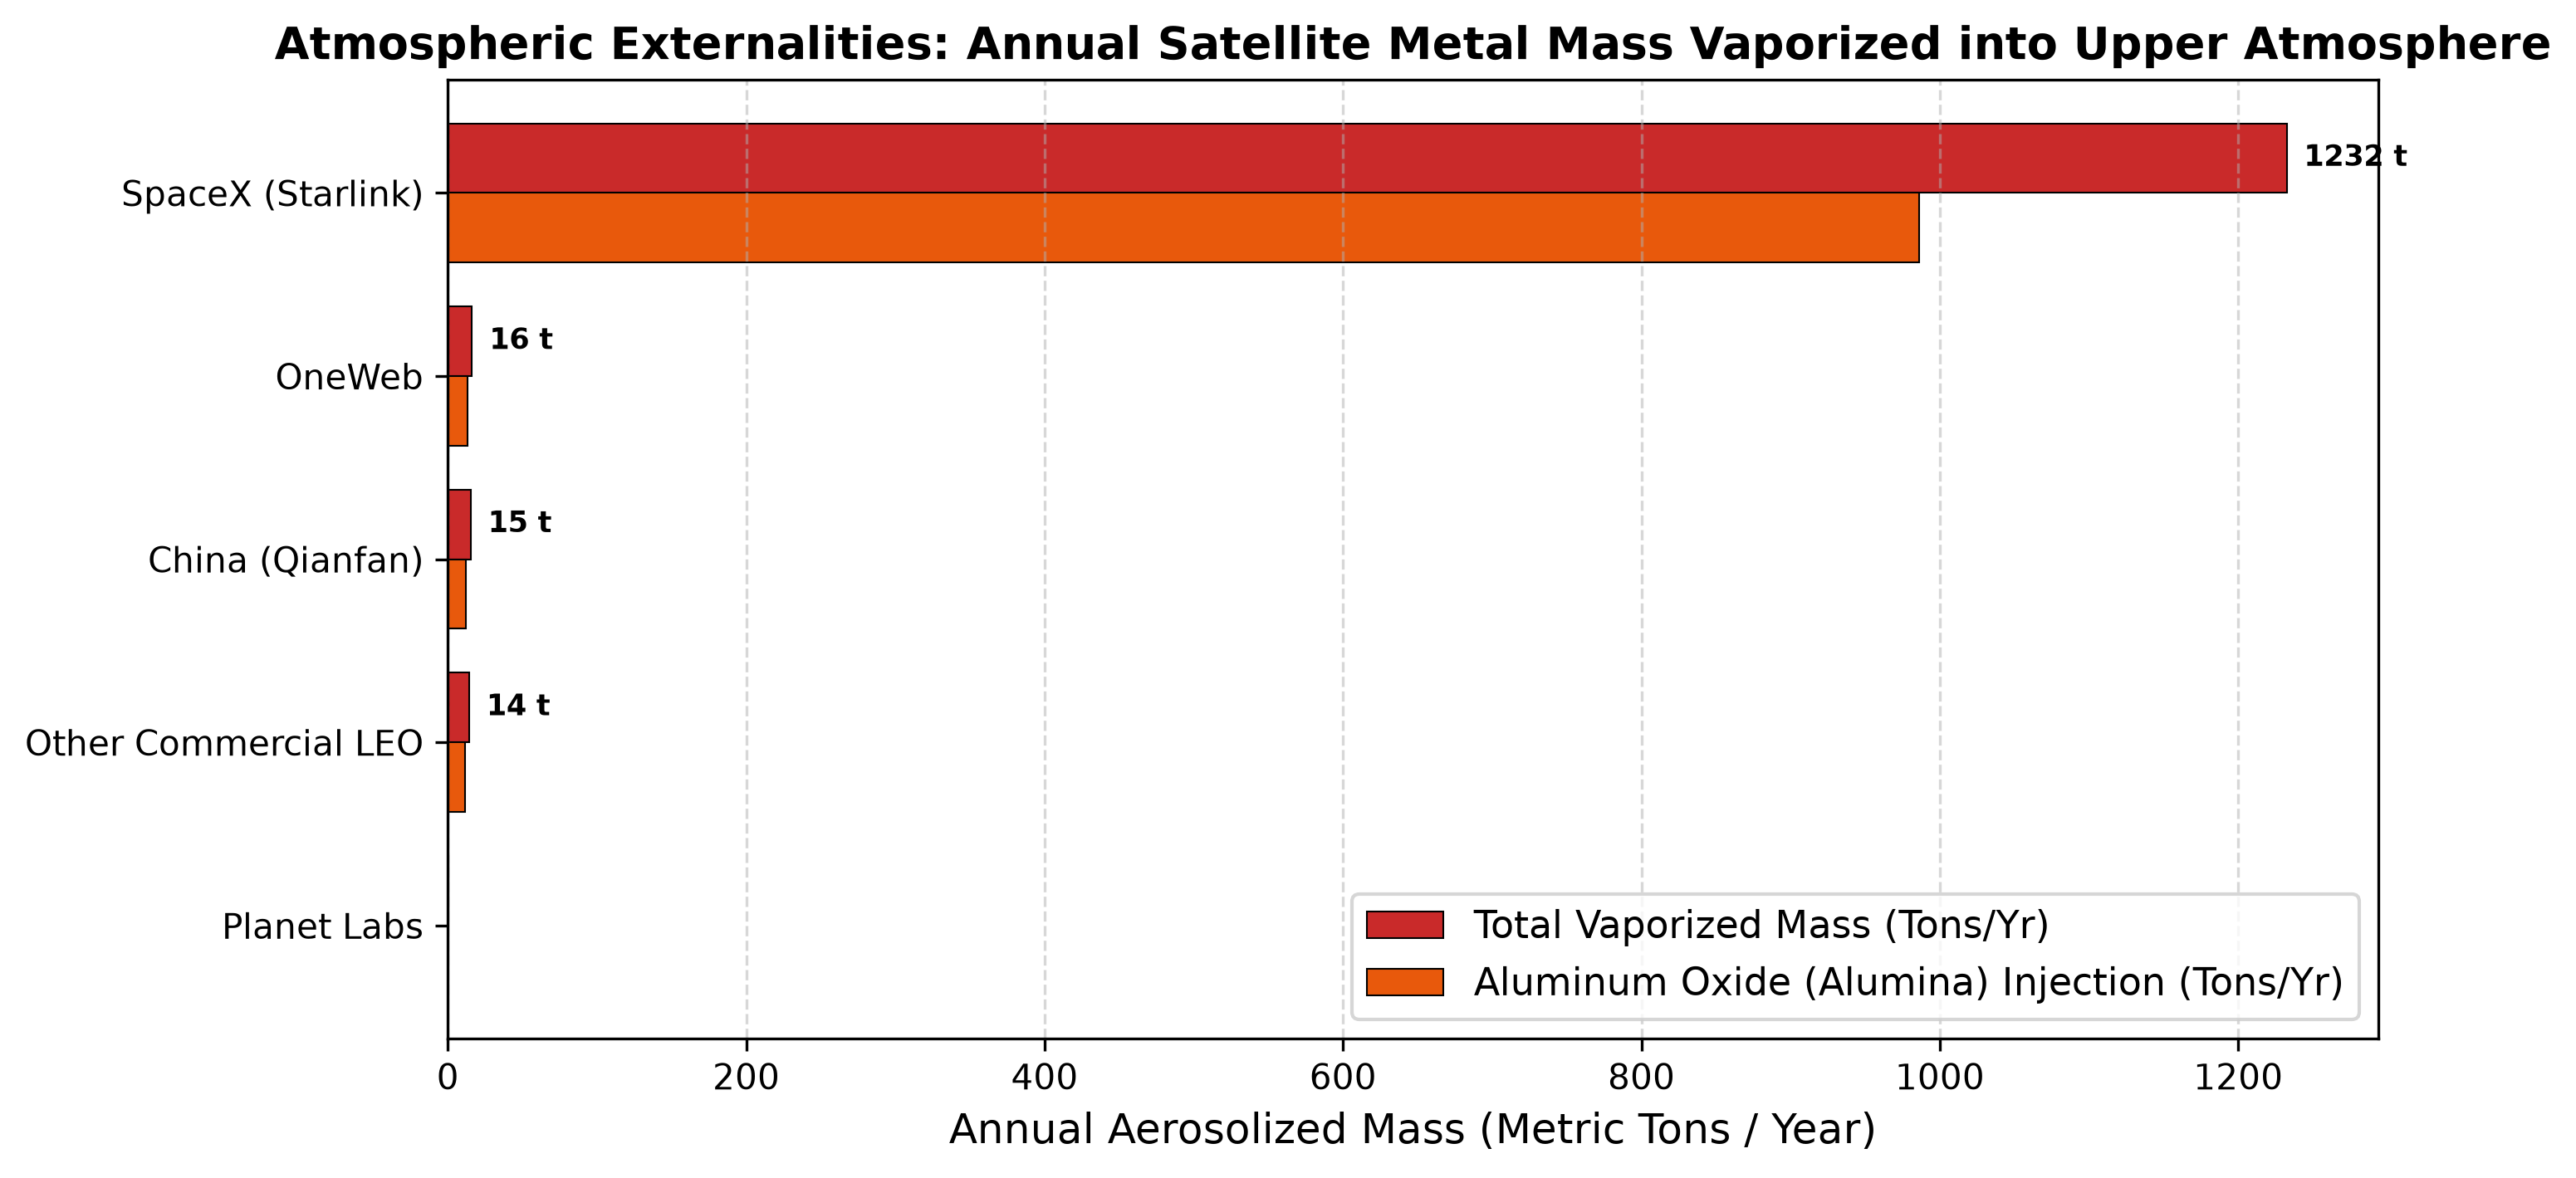

In [23]:
fig_path = "../output/figures/atmospheric_deorbit_mass.png"
if os.path.exists(fig_path):
    display(Image(filename=fig_path))


## 15. Policy Synthesis & Astropolitical Conclusions

### Key Empirical Findings
1. **LEO Enclosure & Monopoly**: SpaceX (Starlink) alone commands **88.1%** of active LEO satellites, producing an HHI of **7,789.3**. The Global South combined holds less than **0.2%** of active orbital real estate.
2. **The 550 km Wall**: Volumetric density in the 540–560 km shell exceeds all other orbital regimes by over 20x, concentrating collision avoidance burdens on new entrants.
3. **Latitudinal Market Optimization**: Inclination selection (~53°) structurally biases satellite ground presence toward affluent Global North latitudes ($45^\circ\text{--}55^\circ\text{N}$), leaving equatorial nations with thinner passes and total dependence on foreign uplink gateways.
4. **The Bogotá Precedent Confirmed**: The geostationary slots above Africa and South America remain predominantly owned by northern industrial powers.
5. **The Climate-Surveillance Paradox**: Regions facing severe climate disruption lack sovereign Earth observation infrastructure.
6. **Atmospheric Externalities**: Continuous constellation replenishment injects over 1,000 metric tons of vaporized metal into the upper atmosphere annually.

### Multilateral Governance Proposals
- **Reform of the ITU "First-Come, First-Served" Doctrine**: Transition to equitable orbital spectrum allocation reserving shells and frequencies for developing nations.
- **Orbital Carrying Capacity & Debris Fees**: Establish satellite density caps and impose an Orbital Commons Conservation Fee on constellations >100 satellites.
- **Montreal Protocol Space Amendments**: Treat mesospheric alumina injection as a regulated ozone-depleting substance.
- **Multilateral Earth Observation Trusts**: Mandate open, real-time satellite imagery access for developing world climate mitigation.
